In [1]:
import os, sys, json, time, hashlib, random
from datetime import datetime

# ---- Mount Drive -----------------------------------------------------------
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    ROOT = '/content/drive/MyDrive/AISL_data'
    ON_COLAB = True
except Exception as e:
    ROOT = os.path.abspath('./AISL_data')
    ON_COLAB = False
    print('Not on Colab -> local root:', ROOT, '|', e)

# ---- Directory scaffold (ALL persistent paths live under ROOT) --------------
DIRS = {k: os.path.join(ROOT, v) for k, v in {
    'data':'microdata', 'fig':'figures', 'tab':'tables', 'ckpt':'checkpoints',
    'log':'logs', 'hf':'cache/hf', 'torch':'cache/torch',
}.items()}
for p in DIRS.values():
    os.makedirs(p, exist_ok=True)

FIGDIR, TABDIR, CKPTDIR, LOGDIR = DIRS['fig'], DIRS['tab'], DIRS['ckpt'], DIRS['log']

# ---- Point every library cache at Drive so downloads happen ONCE -----------
os.environ['HF_HOME']            = DIRS['hf']
os.environ['HF_DATASETS_CACHE']  = os.path.join(DIRS['hf'], 'datasets')
os.environ['TORCH_HOME']         = DIRS['torch']
TORCH_DATA = DIRS['torch']

print('ROOT      :', ROOT)
print('on Colab  :', ON_COLAB)
for k, v in DIRS.items():
    print(f'  {k:6s} -> {v}')

Mounted at /content/drive
ROOT      : /content/drive/MyDrive/AISL_data
on Colab  : True
  data   -> /content/drive/MyDrive/AISL_data/microdata
  fig    -> /content/drive/MyDrive/AISL_data/figures
  tab    -> /content/drive/MyDrive/AISL_data/tables
  ckpt   -> /content/drive/MyDrive/AISL_data/checkpoints
  log    -> /content/drive/MyDrive/AISL_data/logs
  hf     -> /content/drive/MyDrive/AISL_data/cache/hf
  torch  -> /content/drive/MyDrive/AISL_data/cache/torch


In [2]:
# ---- Reproducibility -------------------------------------------------------
SEED = 20260817
import numpy as np
random.seed(SEED); np.random.seed(SEED)
try:
    import torch; torch.manual_seed(SEED)
    torch.backends.cudnn.deterministic = True     # bit-stable reruns of the D5 attacks
    torch.backends.cudnn.benchmark     = False
except Exception:
    pass
print('seed =', SEED)

seed = 20260817


In [3]:
STATUS_PATH = os.path.join(LOGDIR, 'status.json')

def _load_status():
    if os.path.exists(STATUS_PATH):
        try:
            with open(STATUS_PATH) as f: return json.load(f)
        except Exception:
            pass
    return {}

def _save_status(st):
    tmp = STATUS_PATH + '.tmp'
    with open(tmp, 'w') as f: json.dump(st, f, indent=2, sort_keys=True)
    os.replace(tmp, STATUS_PATH)          # atomic; survives an interrupted write

STATUS = _load_status()

def stage_done(name):
    return STATUS.get(name, {}).get('state') == 'ok'

def mark(name, state='ok', **payload):
    STATUS[name] = {'state': state, 'ts': datetime.now().isoformat(timespec='seconds'),
                    **payload}
    _save_status(STATUS)
    icon = {'ok':'[OK]','failed':'[FAIL]','skipped':'[SKIP]'}.get(state,'[..]')
    print(f'{icon} {name}', {k:v for k,v in payload.items() if k != 'traceback'})

def reset_stage(name=None):
    global STATUS
    if name is None: STATUS = {}
    else: STATUS.pop(name, None)
    _save_status(STATUS); print('reset:', name or 'ALL')

# ---- Results registry: every number the manuscript quotes is recorded here --
RESULTS_PATH = os.path.join(TABDIR, 'aisl_results.json')

def _load_results():
    if os.path.exists(RESULTS_PATH):
        try:
            with open(RESULTS_PATH) as f: return json.load(f)
        except Exception: pass
    return {}

RESULTS = _load_results()

def record(**kv):
    RESULTS.update(kv)
    tmp = RESULTS_PATH + '.tmp'
    with open(tmp,'w') as f: json.dump(RESULTS, f, indent=2, sort_keys=True)
    os.replace(tmp, RESULTS_PATH)

def status_report():
    import pandas as pd
    if not STATUS:
        print('no stages recorded yet'); return
    rows = [{'stage':k, 'state':v.get('state'), 'when':v.get('ts'),
             'detail':', '.join(f'{a}={b}' for a,b in v.items()
                                if a not in ('state','ts','traceback'))[:70]}
            for k,v in sorted(STATUS.items())]
    return pd.DataFrame(rows)

print('status file:', STATUS_PATH)
print('stages already complete:', [k for k in STATUS if stage_done(k)] or '(none)')

status file: /content/drive/MyDrive/AISL_data/logs/status.json
stages already complete: ['d34_bbq', 'd3_rtp', 'd3_sms', 'd3_threshold', 'd4_baseline', 'd4_truthfulqa', 'd5_fgsm', 'd5_pgd', 'd5_train', 'tier1_mapped', 'tier1_pew', 'tier1_pew_inventory']


In [4]:
# ---- Plotting: every figure goes to Drive ---------------------------------
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':300,'savefig.dpi':300,
                     'font.size':11,'axes.titlesize':12,'figure.autolayout':True})

def savefig(name):
    # Write a 300-dpi JPG into the Drive figures/ dir, then verify it landed.
    path = os.path.join(FIGDIR, name + '.jpg')
    plt.savefig(path, dpi=300, format='jpg', bbox_inches='tight',
                pil_kwargs={'quality':95})
    ok = os.path.exists(path) and os.path.getsize(path) > 1024
    print(('saved  ' if ok else 'FAILED ') + path +
          (f'  ({os.path.getsize(path)//1024} KB)' if ok else ''))
    if not ok:
        raise IOError('figure did not persist to Drive: ' + path)
    return path

def savetable(df, name):
    p_csv = os.path.join(TABDIR, name + '.csv')
    df.to_csv(p_csv, index=False)
    print('saved ', p_csv)
    return p_csv

# ---- Shared statistics helpers (used by D4 baseline and every D5 stage) -----
import numpy as np
from scipy import stats

def wilson(k, n, z=1.96):
    """95% Wilson score interval for a proportion. Returns (lo, hi) as fractions."""
    if n == 0: return (0.0, 0.0)
    p = k / n
    d = 1 + z*z/n
    c = p + z*z/(2*n)
    h = z * ((p*(1-p)/n + z*z/(4*n*n)) ** 0.5)
    return ((c-h)/d, (c+h)/d)

def wilson_pct(k, n):
    lo, hi = wilson(k, n); return (100*lo, 100*hi)

def mcnemar(correct_a, correct_b):
    """Exact McNemar on two paired boolean correctness vectors over the SAME images.
    Returns (b, c, p) where b = right under A and wrong under B, c = the converse."""
    a = np.asarray(correct_a, dtype=bool); b_ = np.asarray(correct_b, dtype=bool)
    b = int((a & ~b_).sum()); c = int((~a & b_).sum())
    if b + c == 0: return b, c, 1.0
    p = min(1.0, 2*stats.binom.cdf(min(b,c), b+c, 0.5))
    return b, c, float(p)


In [5]:
STAGE = 'd3_rtp'
if stage_done(STAGE) and os.path.exists(os.path.join(FIGDIR,'d3_rtp_toxicity.jpg')):
    print('[SKIP]', STAGE, '->', STATUS[STAGE])
else:
    try:
        import pandas as pd
        from datasets import load_dataset
        t0 = time.time()
        rtp = load_dataset('allenai/real-toxicity-prompts', split='train',
                           cache_dir=os.environ['HF_DATASETS_CACHE'])
        N_TOTAL = len(rtp)
        N_SAMPLE = 20000
        idx = np.random.default_rng(SEED).choice(N_TOTAL, size=min(N_SAMPLE, N_TOTAL),
                                                 replace=False)
        sub = rtp.select(idx.tolist())
        tox = pd.Series([(r['prompt'] or {}).get('toxicity') for r in sub],
                        name='prompt_toxicity').dropna()

        n, mean, pct50 = len(tox), float(tox.mean()), float((tox > 0.5).mean()*100)
        p95, mx = float(tox.quantile(0.95)), float(tox.max())
        print(f'corpus n={N_TOTAL} | sampled={len(sub)} | scored n={n}')
        print(f'mean={mean:.3f} | p95={p95:.3f} | max={mx:.3f} | %>0.5={pct50:.2f}')

        plt.figure()
        ax = tox.plot(kind='hist', bins=40,
                      title='RealToxicityPrompts: prompt toxicity (D3 grounding)')
        ax.set_xlabel('Perspective toxicity score'); ax.set_ylabel('Frequency')
        ax.axvline(0.5, ls='--', lw=1, color='crimson')
        ax.annotate(f'>0.5: {pct50:.2f}%', xy=(0.52, ax.get_ylim()[1]*0.85),
                    fontsize=9, color='crimson')
        savefig('d3_rtp_toxicity'); plt.show()

        savetable(tox.describe().to_frame().reset_index(), 'd3_rtp_summary')
        record(d3_corpus_n=N_TOTAL, d3_n=n, d3_mean=round(mean,3),
               d3_pct_above_half=round(pct50,2), d3_p95=round(p95,3),
               d3_max=round(mx,3), d3_seed=SEED)
        mark(STAGE, n=n, mean=round(mean,3), secs=round(time.time()-t0))
    except Exception as e:
        mark(STAGE, 'failed', error=repr(e)[:200]); raise

[SKIP] d3_rtp -> {'mean': 0.287, 'n': 19906, 'secs': 7, 'state': 'ok', 'ts': '2026-08-17T22:35:58'}


In [6]:
STAGE = 'd4_truthfulqa'
if stage_done(STAGE) and os.path.exists(os.path.join(FIGDIR,'d4_truthfulqa_categories.jpg')):
    print('[SKIP]', STAGE, '->', STATUS[STAGE])
else:
    try:
        import pandas as pd
        from datasets import load_dataset
        t0 = time.time()
        tqa = load_dataset('truthfulqa/truthful_qa', 'generation', split='validation',
                           cache_dir=os.environ['HF_DATASETS_CACHE'])
        cats = pd.Series(tqa['category'], name='category')
        n_q, n_cat = len(cats), cats.nunique()
        vc = cats.value_counts()
        print(f'n questions={n_q} | n categories={n_cat} | largest={vc.index[0]} ({vc.iloc[0]})')

        plt.figure(figsize=(6,5))
        vc.head(15).sort_values().plot(
            kind='barh', title=f'TruthfulQA: questions by category (top 15 of {n_cat})')
        plt.xlabel('questions'); savefig('d4_truthfulqa_categories'); plt.show()

        savetable(vc.rename('n').reset_index().rename(columns={'index':'category'}),
                  'd4_truthfulqa_categories')
        record(d4_n_questions=n_q, d4_n_categories=n_cat,
               d4_top_category=str(vc.index[0]), d4_top_category_n=int(vc.iloc[0]))
        mark(STAGE, n_questions=n_q, n_categories=n_cat, secs=round(time.time()-t0))
    except Exception as e:
        mark(STAGE, 'failed', error=repr(e)[:200]); raise

[SKIP] d4_truthfulqa -> {'n_categories': 38, 'n_questions': 817, 'secs': 2, 'state': 'ok', 'ts': '2026-08-17T22:36:00'}


In [7]:
reset_stage('d4_baseline')

reset: d4_baseline


row-order agreement between configs: 2/817


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

  scored 200/817
  scored 400/817
  scored 600/817
  scored 800/817

gpt2 TruthfulQA MC1: 27.7% correct [95% CI 24.7-30.8] on n=817 questions
chance baseline (mean 1/n_choices) = 22.6%  | mean options per question = 5.0
saved  /content/drive/MyDrive/AISL_data/figures/d4_truthfulqa_baseline.jpg  (290 KB)


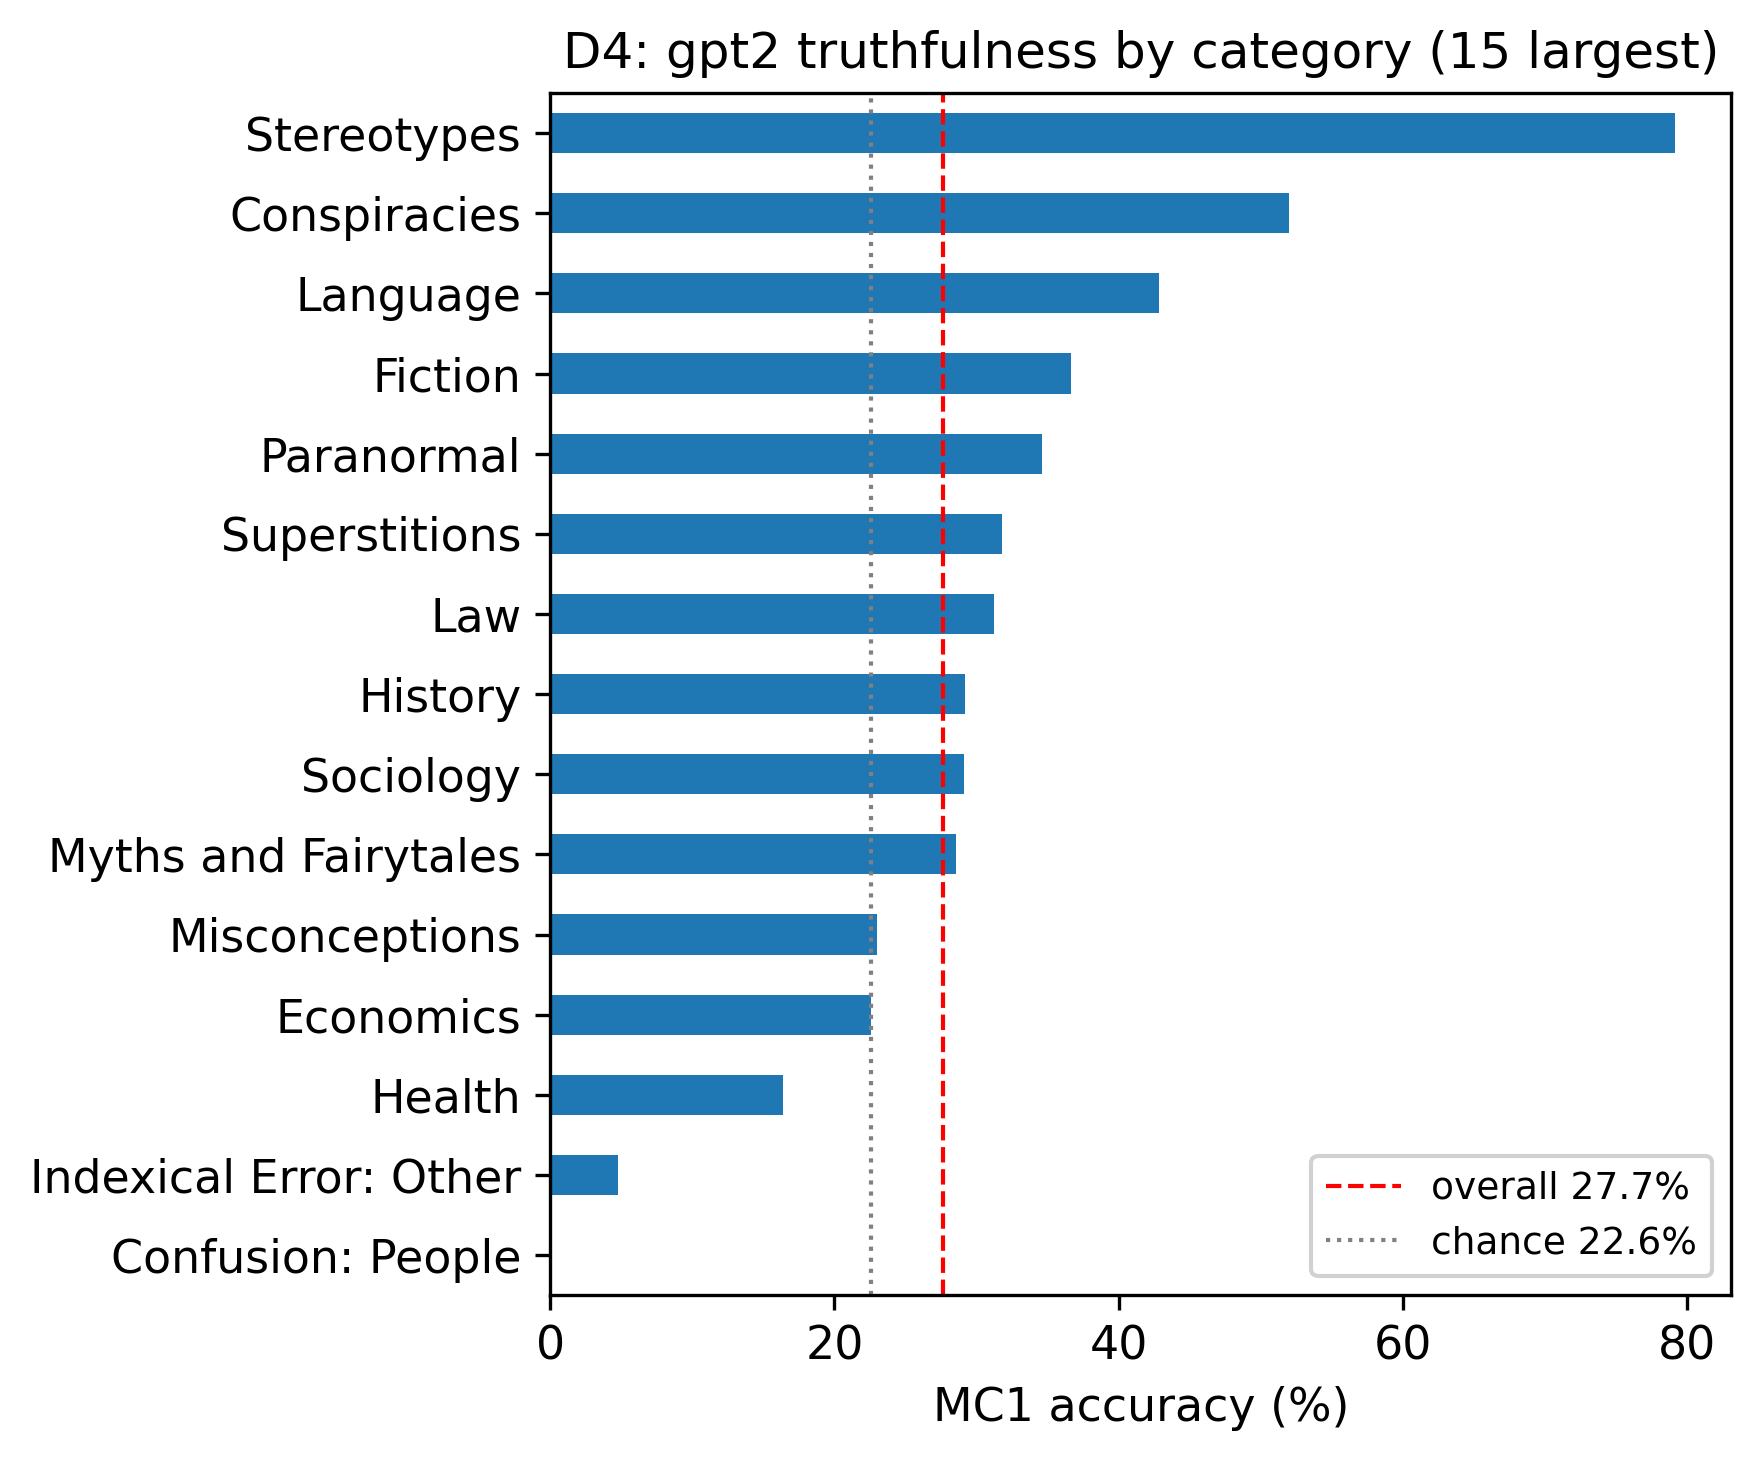

saved  /content/drive/MyDrive/AISL_data/tables/d4_truthfulqa_baseline.csv
[OK] d4_baseline {'model': 'gpt2', 'mc1': 0.2766, 'chance': 0.2261, 'n': 817, 'secs': 89}


In [8]:
# ============ D4 baseline: a measured failure RATE, not a category count =====
# Category counts establish coverage, not difficulty. This scores a real model
# on TruthfulQA MC1 so the dimension reports an observed truthfulness rate.
STAGE = 'd4_baseline'
BASELINE_LM = 'gpt2'          # small, fast, no gating; swap if you want a bigger one

if stage_done(STAGE) and os.path.exists(os.path.join(FIGDIR,'d4_truthfulqa_baseline.jpg')):
    print('[SKIP]', STAGE, '->', STATUS[STAGE])
else:
    try:
        import pandas as pd, torch
        _DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
        from datasets import load_dataset
        from transformers import AutoTokenizer, AutoModelForCausalLM
        t0 = time.time()

        mc = load_dataset('truthfulqa/truthful_qa', 'multiple_choice', split='validation',
                          cache_dir=os.environ['HF_DATASETS_CACHE'])
        gen = load_dataset('truthfulqa/truthful_qa', 'generation', split='validation',
                           cache_dir=os.environ['HF_DATASETS_CACHE'])
        # Join on question text, not row position: the two configs are not
        # guaranteed to share row order.
        _norm = lambda s: ' '.join(str(s).split()).lower()
        gq, gc, mq = list(gen['question']), list(gen['category']), list(mc['question'])
        same_pos = sum(_norm(a) == _norm(b) for a, b in zip(gq, mq))
        print(f'row-order agreement between configs: {same_pos}/{len(mq)}')
        q2cat = {_norm(q): c for q, c in zip(gq, gc)}
        cats, n_fallback = [], 0
        for i, q in enumerate(mq):
            c = q2cat.get(_norm(q))
            if c is None:                     # text differs between configs: use row position
                c = gc[i]; n_fallback += 1
                print(f'  no text match, MC row {i}: {q[:70]!r}')
                print(f'     -> positional category {c!r} (generation row: {gq[i][:70]!r})')
            cats.append(c)
        if n_fallback > 5:
            raise RuntimeError(f'{n_fallback} MC questions unmatched; configs are not aligned')

        tok = AutoTokenizer.from_pretrained(BASELINE_LM, cache_dir=os.environ['HF_HOME'])
        lm  = AutoModelForCausalLM.from_pretrained(BASELINE_LM,
                                                   cache_dir=os.environ['HF_HOME']).to(_DEV).eval()

        @torch.no_grad()
        def choice_logprob(question, answer):
            """Mean per-token log-likelihood of `answer` continuing `question`."""
            q_ids = tok(f'Q: {question}\nA:', return_tensors='pt').input_ids
            a_ids = tok(f' {answer}', return_tensors='pt').input_ids
            ids   = torch.cat([q_ids, a_ids], dim=1).to(_DEV)
            logits = lm(ids).logits[:, :-1]
            tgt    = ids[:, 1:]
            lp     = torch.log_softmax(logits, -1).gather(2, tgt.unsqueeze(-1)).squeeze(-1)
            return lp[0, q_ids.shape[1]-1:].mean().item()

        correct, per_cat, n_choices = [], {}, []
        for i, row in enumerate(mc):
            q             = row['question']
            labels, texts = row['mc1_targets']['labels'], row['mc1_targets']['choices']
            scores        = [choice_logprob(q, t) for t in texts]
            hit           = int(labels[int(np.argmax(scores))] == 1)
            correct.append(hit); n_choices.append(len(texts))
            per_cat.setdefault(cats[i], []).append(hit)
            if (i+1) % 200 == 0: print(f'  scored {i+1}/{len(mc)}')

        n, k  = len(correct), int(sum(correct))
        mc1   = k / n
        lo,hi = wilson_pct(k, n)

        # Chance level: MC1 items have a variable number of options, so the
        # accuracy is uninterpretable without it.
        chance = float(np.mean([1/c for c in n_choices]))
        print(f'\n{BASELINE_LM} TruthfulQA MC1: {mc1*100:.1f}% correct '
              f'[95% CI {lo:.1f}-{hi:.1f}] on n={n} questions')
        print(f'chance baseline (mean 1/n_choices) = {chance*100:.1f}%  '
              f'| mean options per question = {np.mean(n_choices):.1f}')

        cat_acc = (pd.Series({c: 100*np.mean(v) for c,v in per_cat.items()})
                     .rename('accuracy_pct'))
        cat_n   = pd.Series({c: len(v) for c,v in per_cat.items()}, name='n')
        tbl     = pd.concat([cat_acc, cat_n], axis=1).sort_values('n', ascending=False)

        plt.figure(figsize=(6,5))
        top = tbl.head(15).sort_values('accuracy_pct')
        top.accuracy_pct.plot(kind='barh', label='_nolegend_')
        plt.axvline(mc1*100, ls='--', lw=1, color='red', label=f'overall {mc1*100:.1f}%')
        plt.axvline(chance*100, ls=':', lw=1, color='grey', label=f'chance {chance*100:.1f}%')
        plt.legend(loc='lower right', fontsize=9, framealpha=0.9)
        plt.xlabel('MC1 accuracy (%)')
        plt.title(f'D4: {BASELINE_LM} truthfulness by category (15 largest)')
        savefig('d4_truthfulqa_baseline'); plt.show()

        savetable(tbl.reset_index().rename(columns={'index':'category'}),
                  'd4_truthfulqa_baseline')
        record(d4_mc1_acc=round(mc1,4), d4_mc1_model=BASELINE_LM, d4_mc1_n=n,
               d4_mc1_ci=f'{lo:.1f}--{hi:.1f}',
               d4_mc1_chance=round(chance,4),
               d4_mc1_worst=str(tbl.accuracy_pct.idxmin()))
        mark(STAGE, model=BASELINE_LM, mc1=round(mc1,4), chance=round(chance,4),
             n=n, secs=round(time.time()-t0))
    except Exception as e:
        # Never let the baseline block the rest of the run: record and move on.
        mark(STAGE, 'skipped', error=repr(e)[:200])
        print('D4 baseline skipped -- the category-count result is unaffected.')

In [9]:
STAGE = 'd34_bbq'
BBQ_CONFIGS = ['age','disabilityStatus','genderIdentity','nationality',
               'physicalAppearance','raceEthnicity','raceXSes','raceXGender',
               'religion','ses','sexualOrientation']

if stage_done(STAGE) and os.path.exists(os.path.join(FIGDIR,'d34_bbq_configs.jpg')):
    print('[SKIP]', STAGE, '->', STATUS[STAGE])
else:
    try:
        import pandas as pd
        from datasets import load_dataset
        t0, counts, failed = time.time(), {}, []
        for cfg in BBQ_CONFIGS:
            try:
                ds = load_dataset('walledai/BBQ', split=cfg,
                                  cache_dir=os.environ['HF_DATASETS_CACHE'])
                counts[cfg] = len(ds)
                print(f'  {cfg:20s} {len(ds):>7,}')
            except Exception as ee:
                failed.append(cfg); print(f'  {cfg:20s} FAILED {repr(ee)[:80]}')
        if not counts:
            raise RuntimeError('no BBQ config loaded; check dataset card for split names')

        s = pd.Series(counts).sort_values()
        total = int(s.sum())
        print(f'BBQ total items={total:,} across {len(s)} attribute categories')

        plt.figure(figsize=(6,4.5))
        s.plot(kind='barh', title='BBQ: items per social-attribute category (D3/D4)')
        plt.xlabel('items'); savefig('d34_bbq_configs'); plt.show()

        savetable(s.rename('n').reset_index().rename(columns={'index':'attribute'}),
                  'd34_bbq_counts')
        record(bbq_total=total, bbq_n_categories=int(len(s)),
               bbq_failed_configs=len(failed))
        mark(STAGE, total=total, categories=int(len(s)), failed=len(failed),
             secs=round(time.time()-t0))
    except Exception as e:
        mark(STAGE, 'failed', error=repr(e)[:200]); print('BBQ unavailable:', e)

[SKIP] d34_bbq -> {'categories': 11, 'failed': 0, 'secs': 11, 'state': 'ok', 'total': 58492, 'ts': '2026-08-17T22:36:11'}


In [10]:
# torchattacks pinned, and installed --no-deps so its requests==2.25.1 pin
# does not downgrade the Colab environment (that was the v2 dependency conflict).
try:
    import torchattacks
    assert torchattacks.__version__.startswith('3.5')
except Exception:
    !pip -q install --no-deps torchattacks==3.5.1
    import torchattacks

import torch, torchvision, torchvision.transforms as T
from torch import nn
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEV, '| torch', torch.__version__, '| torchattacks', torchattacks.__version__)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 142.0/142.0 kB 1.8 MB/s eta 0:00:00
device: cuda | torch 2.11.0+cu130 | torchattacks 3.5.1


In [11]:
# ---- CIFAR-10 cached on Drive: downloads once, then reused -----------------
tf = T.Compose([T.ToTensor()])
train_ds = torchvision.datasets.CIFAR10(TORCH_DATA, train=True,  download=True, transform=tf)
test_ds  = torchvision.datasets.CIFAR10(TORCH_DATA, train=False, download=True, transform=tf)
train_ld = torch.utils.data.DataLoader(train_ds, batch_size=256, shuffle=True,  num_workers=2)
test_ld  = torch.utils.data.DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2)
print(f'CIFAR-10 cached at {TORCH_DATA} | train={len(train_ds):,} test={len(test_ds):,}')

CIFAR-10 cached at /content/drive/MyDrive/AISL_data/cache/torch | train=50,000 test=10,000


In [12]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(
            nn.Conv2d(3,32,3,1,1),  nn.BatchNorm2d(32),  nn.ReLU(),
            nn.Conv2d(32,32,3,1,1), nn.BatchNorm2d(32),  nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,1,1), nn.BatchNorm2d(64),  nn.ReLU(),
            nn.Conv2d(64,64,3,1,1), nn.BatchNorm2d(64),  nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Dropout(0.3), nn.Linear(64*8*8,256), nn.ReLU(),
            nn.Linear(256,10))
    def forward(self, x): return self.f(x)

# ---- Multi-seed: three independently initialised and trained models ---------
SEEDS = [20260817, 20260818, 20260819]
EPOCHS, MIN_CLEAN_ACC = 15, 0.60      # gate: below this the sweep is meaningless
N_EVAL_BATCHES = None                 # None = the FULL 10,000-image test set

def ckpt_path(seed):
    return os.path.join(CKPTDIR, f'cifar10_cnn_seed{seed}.pt')

@torch.no_grad()
def clean_accuracy(model, loader, n_batches=N_EVAL_BATCHES):
    model.eval(); c = t = 0
    for i,(x,y) in enumerate(loader):
        if n_batches is not None and i >= n_batches: break
        x,y = x.to(DEV), y.to(DEV)
        c += (model(x).argmax(1) == y).sum().item(); t += y.size(0)
    return c/t

def save_ckpt(model, opt, epoch, acc, seed):
    p = ckpt_path(seed); tmp = p + '.tmp'
    torch.save({'epoch':epoch, 'model':model.state_dict(),
                'opt':opt.state_dict(), 'test_acc':acc, 'seed':seed}, tmp)
    os.replace(tmp, p)                          # atomic: no half-written checkpoint

def load_ckpt(model, opt=None, seed=None):
    p = ckpt_path(seed)
    if not os.path.exists(p): return 0, None
    ck = torch.load(p, map_location=DEV)
    model.load_state_dict(ck['model'])
    if opt is not None and 'opt' in ck: opt.load_state_dict(ck['opt'])
    return ck.get('epoch',0), ck.get('test_acc')

for s in SEEDS:
    print(f'checkpoint seed {s}: {ckpt_path(s)} | exists: {os.path.exists(ckpt_path(s))}')
print(f'evaluation set: {"FULL test set (10,000 images)" if N_EVAL_BATCHES is None else str(N_EVAL_BATCHES*256)+" images"}')


checkpoint seed 20260817: /content/drive/MyDrive/AISL_data/checkpoints/cifar10_cnn_seed20260817.pt | exists: True
checkpoint seed 20260818: /content/drive/MyDrive/AISL_data/checkpoints/cifar10_cnn_seed20260818.pt | exists: True
checkpoint seed 20260819: /content/drive/MyDrive/AISL_data/checkpoints/cifar10_cnn_seed20260819.pt | exists: True
evaluation set: FULL test set (10,000 images)


In [13]:
STAGE = 'd5_train'
lossf = nn.CrossEntropyLoss()
MODELS, per_seed_acc = {}, {}
t0 = time.time()

for seed in SEEDS:
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

    m   = Net().to(DEV)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    start_epoch, prev_acc = load_ckpt(m, opt, seed)

    if start_epoch >= EPOCHS and prev_acc and prev_acc >= MIN_CLEAN_ACC:
        print(f'[SKIP] seed {seed}: already trained {start_epoch} epochs, acc {prev_acc:.4f}')
        acc = prev_acc
    else:
        if start_epoch: print(f'seed {seed}: resumed at epoch {start_epoch} (acc {prev_acc:.4f})')
        for ep in range(start_epoch, EPOCHS):
            m.train(); run = 0.0
            for x,y in train_ld:
                x,y = x.to(DEV), y.to(DEV)
                opt.zero_grad(); loss = lossf(m(x), y); loss.backward(); opt.step()
                run += loss.item()*y.size(0)
            acc = clean_accuracy(m, test_ld)
            save_ckpt(m, opt, ep+1, acc, seed)
            print(f'  seed {seed}  epoch {ep+1:>2}/{EPOCHS}  loss={run/len(train_ds):.4f}  test_acc={acc:.4f}')
    MODELS[seed] = m
    per_seed_acc[seed] = float(acc)

accs      = np.array([per_seed_acc[s] for s in SEEDS])
clean_acc = float(accs.mean())            # the number the manuscript quotes
clean_sd  = float(accs.std(ddof=1)) if len(accs) > 1 else 0.0
model     = MODELS[SEEDS[0]]              # back-compat for any single-model cell

print(f'\nper-seed clean accuracy: ' + ', '.join(f'{s}={per_seed_acc[s]:.4f}' for s in SEEDS))
print(f'mean clean accuracy = {clean_acc:.4f}  (sd {clean_sd:.4f}, n_seeds={len(SEEDS)})')

record(d5_clean_acc=round(clean_acc,4), d5_clean_sd_pts=round(clean_sd*100,2),
       d5_epochs=EPOCHS, d5_n_seeds=len(SEEDS),
       d5_per_seed_acc={str(s): round(per_seed_acc[s],4) for s in SEEDS})
mark(STAGE, epochs=EPOCHS, n_seeds=len(SEEDS), clean_acc=round(clean_acc,4),
     clean_sd=round(clean_sd,4), secs=round(time.time()-t0))


[SKIP] seed 20260817: already trained 15 epochs, acc 0.7975
[SKIP] seed 20260818: already trained 15 epochs, acc 0.7885
[SKIP] seed 20260819: already trained 15 epochs, acc 0.7937

per-seed clean accuracy: 20260817=0.7975, 20260818=0.7885, 20260819=0.7937
mean clean accuracy = 0.7932  (sd 0.0045, n_seeds=3)
[OK] d5_train {'epochs': 15, 'n_seeds': 3, 'clean_acc': 0.7932, 'clean_sd': 0.0045, 'secs': 3}


  eps=   0/255   acc= 79.32%  [95% CI 78.86-79.78]  seed range 78.85-79.75%
  eps=   1/255   acc= 41.10%  [95% CI 40.55-41.66]  seed range 39.26-42.81%
  eps=   2/255   acc= 19.65%  [95% CI 19.20-20.10]  seed range 17.61-21.52%
  eps=   4/255   acc=  5.78%  [95% CI  5.52- 6.05]  seed range 4.48-6.82%
  eps=   8/255   acc=  2.26%  [95% CI  2.10- 2.43]  seed range 1.40-3.08%
  eps=  16/255   acc=  2.13%  [95% CI  1.98- 2.30]  seed range 1.92-2.51%
saved  /content/drive/MyDrive/AISL_data/figures/d5_fgsm_sweep.jpg  (185 KB)


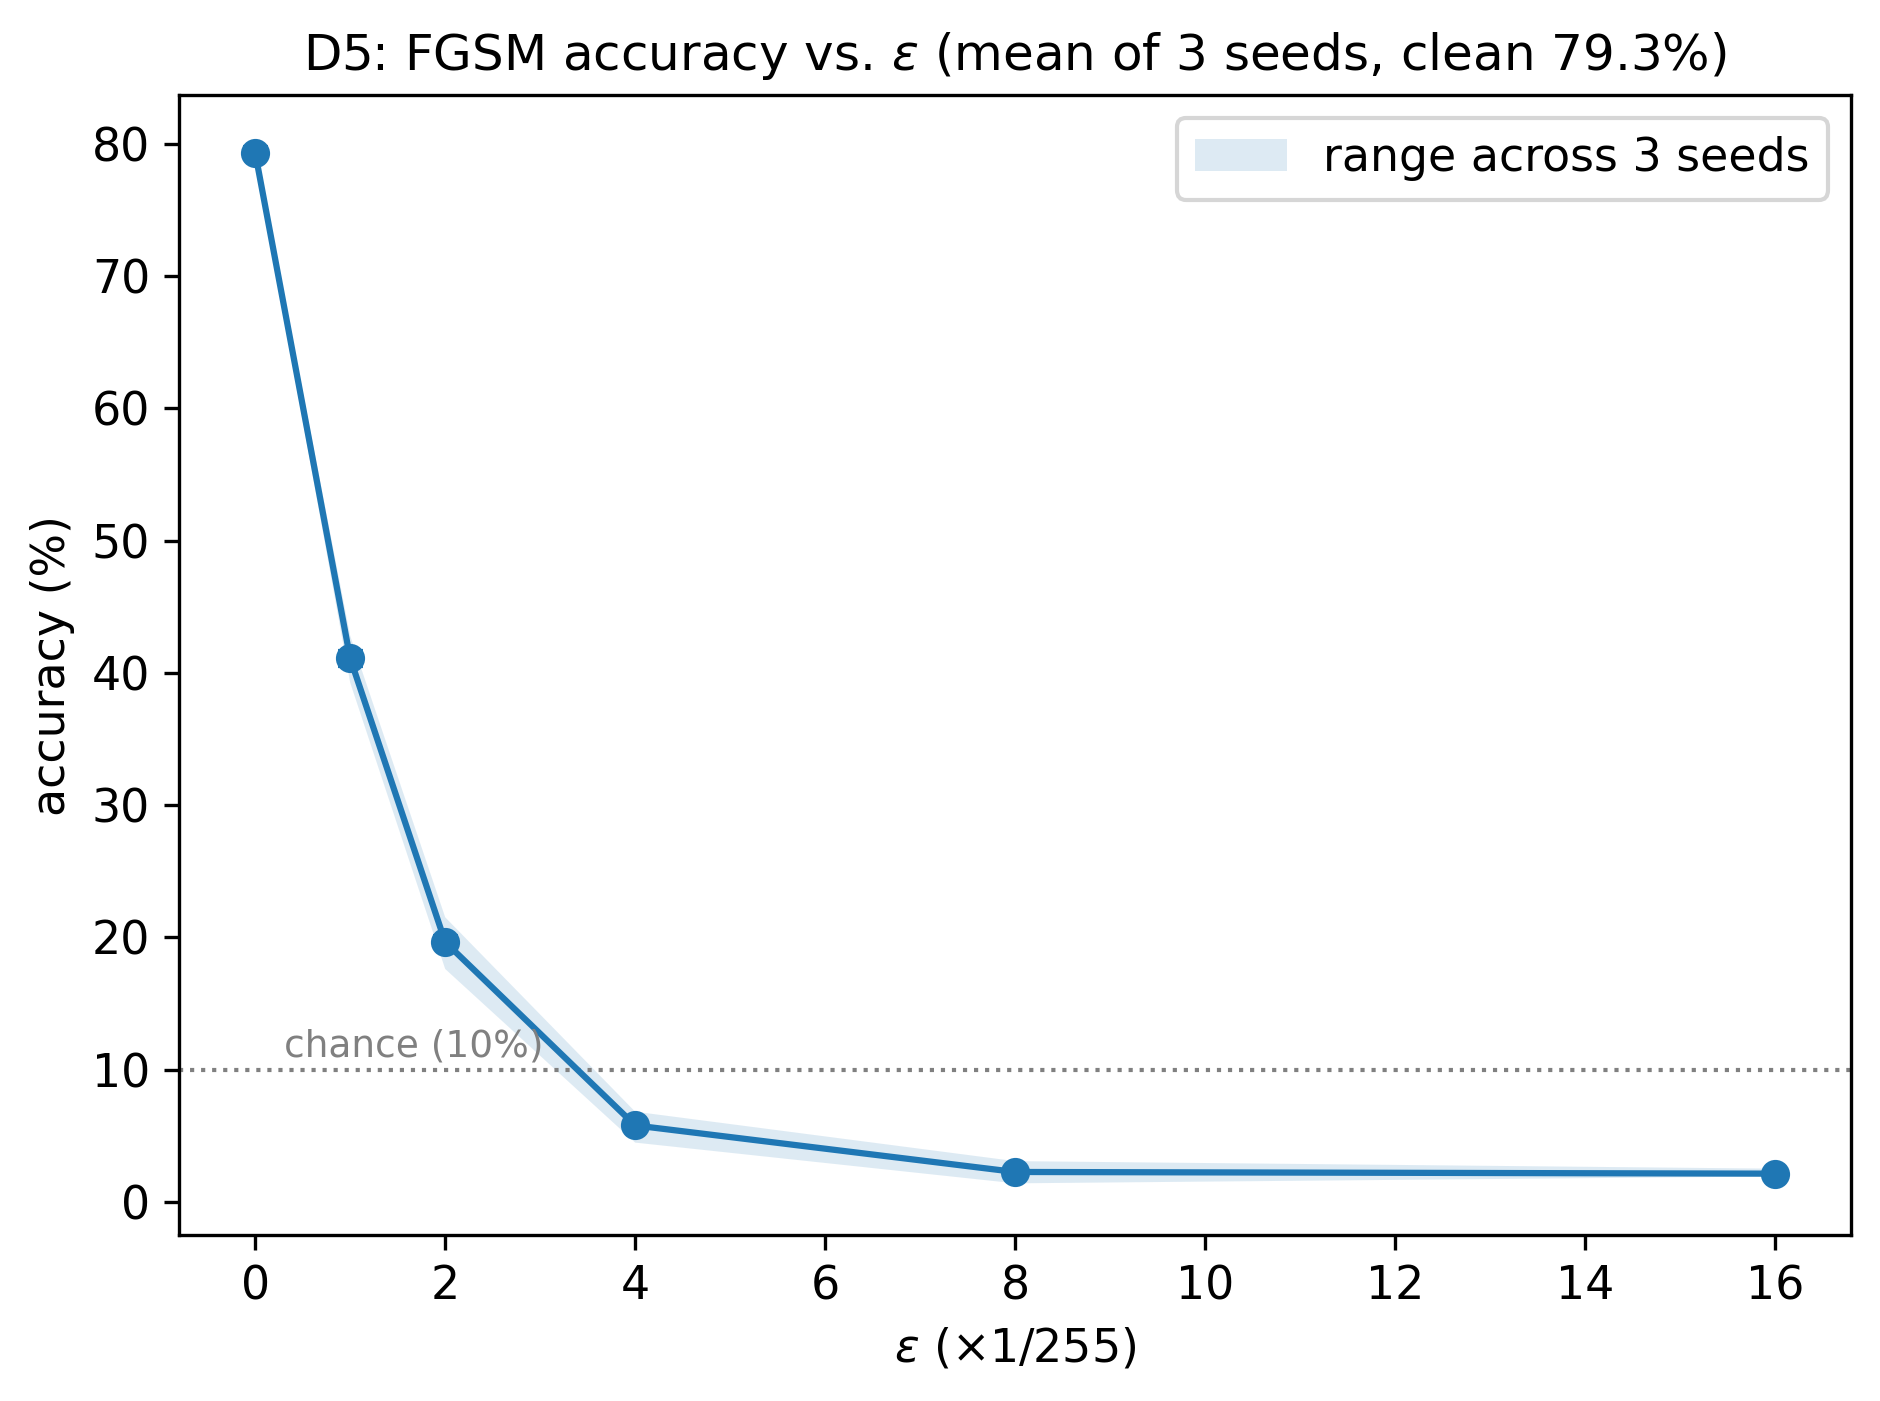

saved  /content/drive/MyDrive/AISL_data/tables/d5_fgsm_sweep.csv
[OK] d5_fgsm {'clean': 0.7932, 'at_eps8': 0.0226, 'n_eval': 10000, 'n_seeds': 3, 'secs': 33}


In [14]:
STAGE = 'd5_fgsm'
if clean_acc < MIN_CLEAN_ACC:
    mark(STAGE, 'failed', clean_acc=round(float(clean_acc),4), gate=MIN_CLEAN_ACC)
    raise RuntimeError(
        f'SANITY GATE: mean clean accuracy {clean_acc:.3f} < {MIN_CLEAN_ACC}. '
        'The model is not adequately trained, so an FGSM sweep would measure noise, '
        'not attack effect. This is exactly the v1 failure. Train more epochs '
        '(raise EPOCHS) or load a pretrained checkpoint before continuing.')

import pandas as pd

def correctness_under_attack(model, loader, atk, n_batches=N_EVAL_BATCHES):
    """Per-image correctness over the evaluation set. Returns a boolean array."""
    model.eval(); out = []
    for i,(x,y) in enumerate(loader):
        if n_batches is not None and i >= n_batches: break
        x,y = x.to(DEV), y.to(DEV)
        if atk is not None: x = atk(x, y)
        with torch.no_grad():
            out.append((model(x).argmax(1) == y).cpu().numpy())
    return np.concatenate(out)

t0 = time.time()
eps_grid = [0, 1/255, 2/255, 4/255, 8/255, 16/255]
rows, N_EVAL = [], None

for e in eps_grid:
    per_seed = []
    for s in SEEDS:
        torch.manual_seed(s)
        m = MODELS[s]
        atk = torchattacks.FGSM(m, eps=e) if e > 0 else None
        corr = correctness_under_attack(m, test_ld, atk)
        N_EVAL = len(corr)
        per_seed.append(corr.mean())
    per_seed = np.array(per_seed)
    # Wilson interval on the pooled evaluation (n_seeds x N_EVAL image decisions)
    k = int(round(per_seed.mean() * N_EVAL * len(SEEDS)))
    lo, hi = wilson_pct(k, N_EVAL*len(SEEDS))
    rows.append({'eps_over_255': e*255, 'acc_mean': per_seed.mean(),
                 'acc_min': per_seed.min(), 'acc_max': per_seed.max(),
                 'ci_lo_pct': lo, 'ci_hi_pct': hi})
    print(f'  eps={e*255:>4.0f}/255   acc={per_seed.mean()*100:6.2f}%  '
          f'[95% CI {lo:5.2f}-{hi:5.2f}]  seed range {per_seed.min()*100:.2f}-{per_seed.max()*100:.2f}%')

sweep = pd.DataFrame(rows)
sweep['accuracy_pct'] = sweep.acc_mean*100

plt.figure()
plt.errorbar(sweep.eps_over_255, sweep.accuracy_pct,
             yerr=[sweep.accuracy_pct - sweep.ci_lo_pct, sweep.ci_hi_pct - sweep.accuracy_pct],
             fmt='o-', capsize=3)
plt.fill_between(sweep.eps_over_255, sweep.acc_min*100, sweep.acc_max*100,
                 alpha=0.15, label=f'range across {len(SEEDS)} seeds')
plt.axhline(10, ls=':', lw=1, color='grey')
plt.annotate('chance (10%)', xy=(0.3, 11), fontsize=9, color='grey')
plt.xlabel(r'$\epsilon$ ($\times$1/255)'); plt.ylabel('accuracy (%)'); plt.legend()
plt.title(f'D5: FGSM accuracy vs. $\\epsilon$ (mean of {len(SEEDS)} seeds, clean {clean_acc*100:.1f}%)')
savefig('d5_fgsm_sweep'); plt.show()

savetable(sweep, 'd5_fgsm_sweep')
r8   = sweep.loc[sweep.eps_over_255==8].iloc[0]
eps8 = float(r8.acc_mean)
record(d5_acc_eps8=round(eps8,4), d5_drop_eps8=round(float(clean_acc)-eps8,4),
       d5_eps_max=16, d5_n_eval=int(N_EVAL),
       d5_eps8_ci=f'{r8.ci_lo_pct:.1f}--{r8.ci_hi_pct:.1f}',
       d5_eps8_seed_range=f'{r8.acc_min*100:.1f}--{r8.acc_max*100:.1f}')
mark(STAGE, clean=round(float(clean_acc),4), at_eps8=round(eps8,4),
     n_eval=int(N_EVAL), n_seeds=len(SEEDS), secs=round(time.time()-t0))


construction bands (%): {'[0,.25)': np.float64(60.0), '[.25,.5)': np.float64(18.2), '[.5,.75)': np.float64(11.3), '[.75,1]': np.float64(10.5)}
>0.3 35.62% | >0.5 21.82% | >0.7 12.40% | swing 23.2 pts
ambiguous 0.4-0.6 band: 10.47% of prompts
saved  /content/drive/MyDrive/AISL_data/figures/d3_threshold_sensitivity.jpg  (254 KB)


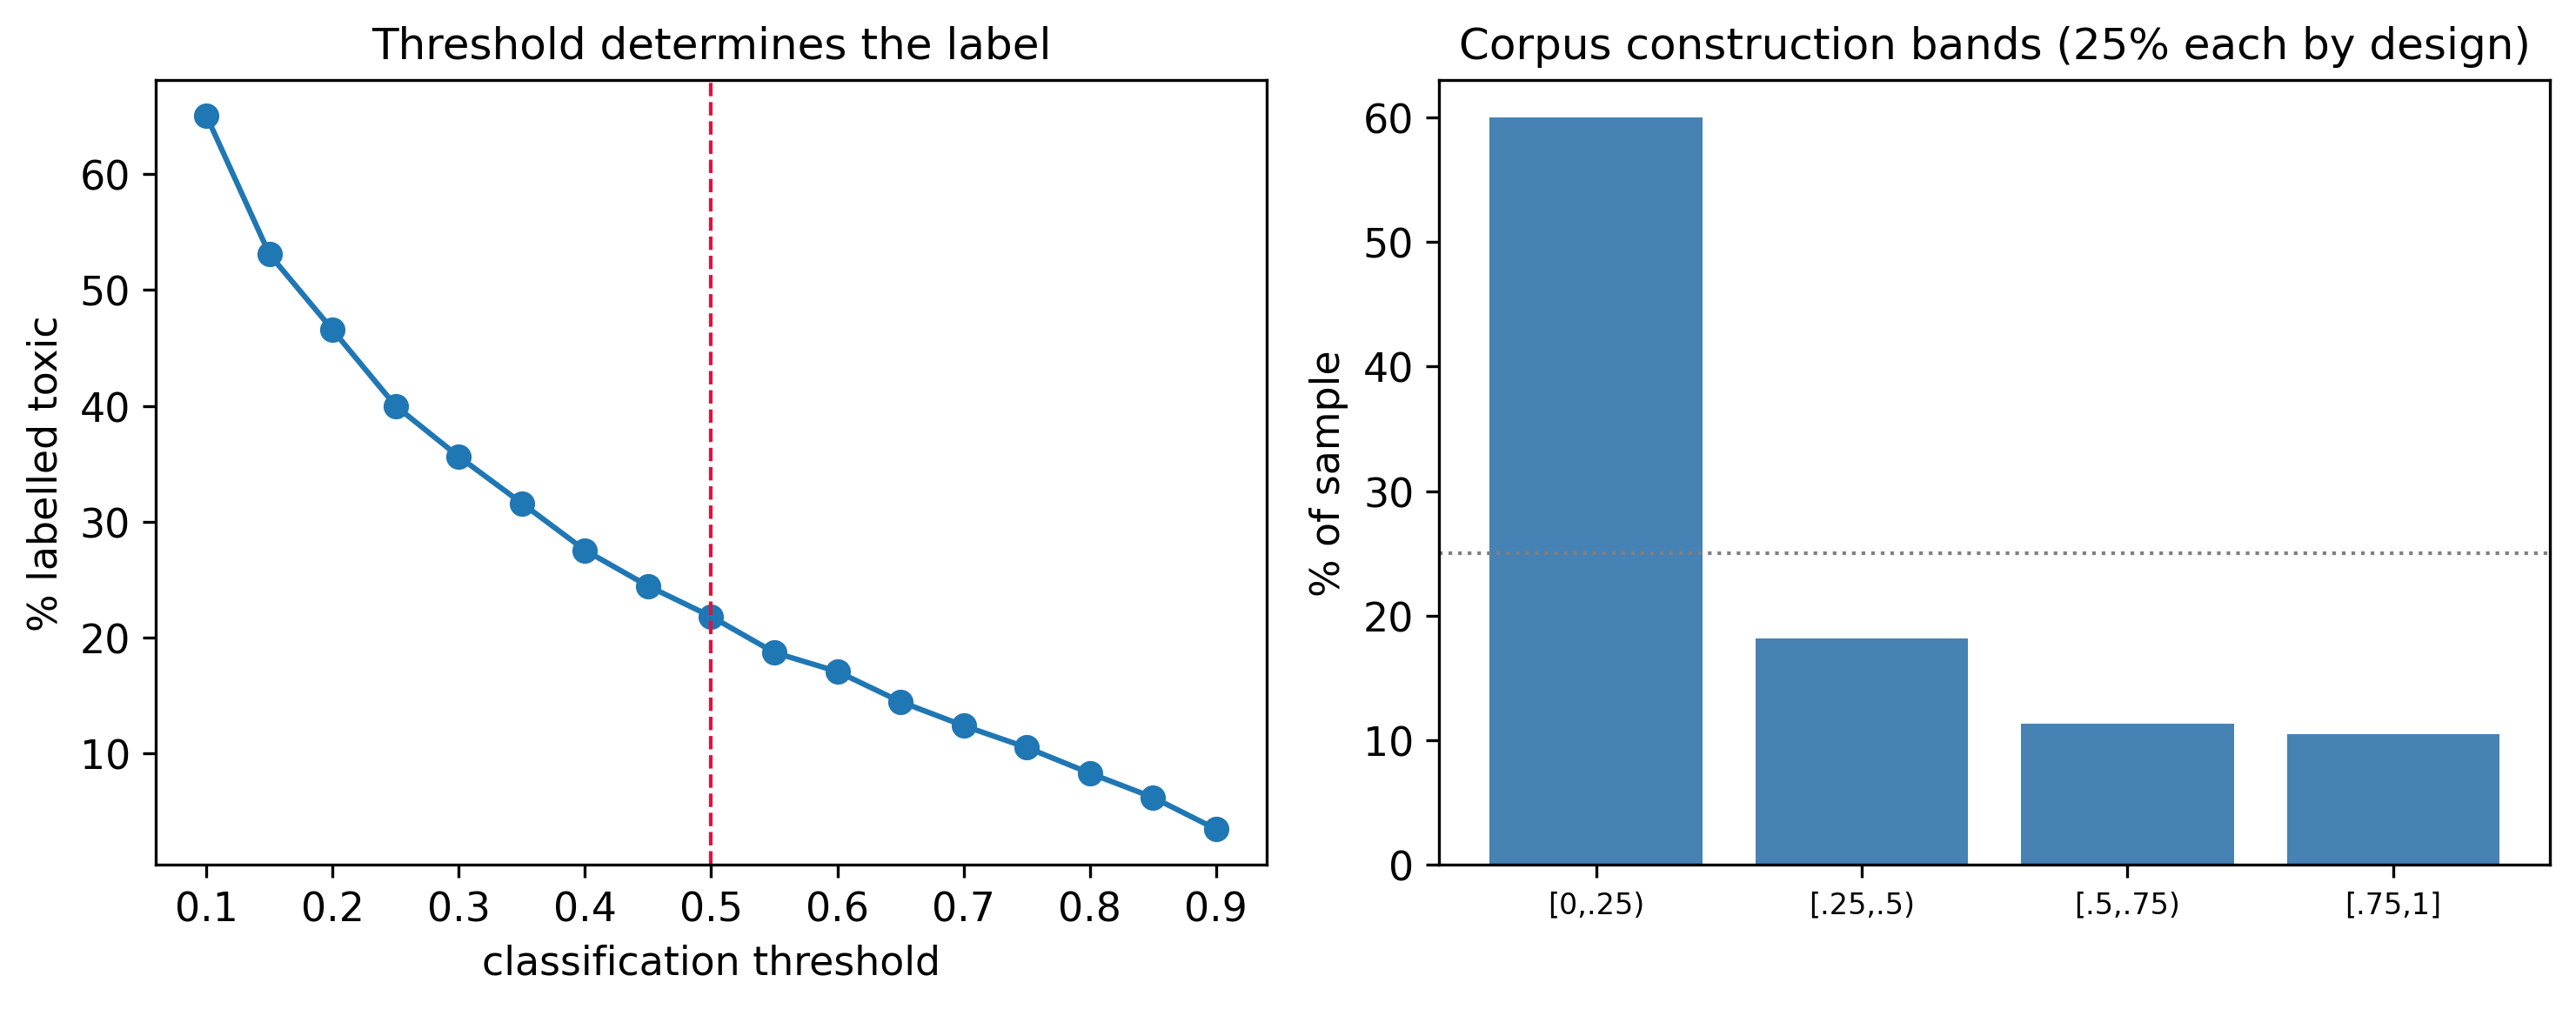

saved  /content/drive/MyDrive/AISL_data/tables/d3_threshold_sensitivity.csv
[OK] d3_threshold {'swing_pts': 23.2, 'ambiguous_pct': 10.47}


In [15]:
# ============ ADDENDUM A: D3 threshold sensitivity + stratification =========
# Grounds the DEFENSIBLE claim (detection is a threshold decision on a
# continuous score) instead of the indefensible one (a web base rate).
STAGE = 'd3_threshold'
import pandas as pd
from datasets import load_dataset

rtp = load_dataset('allenai/real-toxicity-prompts', split='train',
                   cache_dir=os.environ['HF_DATASETS_CACHE'])          # cached
idx = np.random.default_rng(SEED).choice(len(rtp), size=20000, replace=False)
tox = pd.Series([(r['prompt'] or {}).get('toxicity')
                 for r in rtp.select(idx.tolist())]).dropna()

grid  = np.round(np.arange(0.10, 0.95, 0.05), 2)
share = np.array([(tox > t).mean()*100 for t in grid])
at3, at5, at7 = [float((tox > t).mean()*100) for t in (0.3, 0.5, 0.7)]
amb = float(((tox >= 0.4) & (tox <= 0.6)).mean()*100)

# How the four construction bands survive prompt/continuation rescoring
bands = pd.cut(tox, [0,.25,.5,.75,1.001], right=False,
               labels=['[0,.25)','[.25,.5)','[.5,.75)','[.75,1]']).value_counts().sort_index()
band_pct = (bands/len(tox)*100).round(1)
print('construction bands (%):', dict(zip(band_pct.index.astype(str), band_pct.values)))
print(f'>0.3 {at3:.2f}% | >0.5 {at5:.2f}% | >0.7 {at7:.2f}% | swing {at3-at7:.1f} pts')
print(f'ambiguous 0.4-0.6 band: {amb:.2f}% of prompts')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
a1.plot(grid, share, 'o-')
a1.axvline(0.5, ls='--', lw=1, color='crimson')
a1.set_xlabel('classification threshold'); a1.set_ylabel('% labelled toxic')
a1.set_title('Threshold determines the label')
a2.bar(band_pct.index.astype(str), band_pct.values, color='steelblue')
a2.axhline(25, ls=':', lw=1, color='grey')
a2.set_ylabel('% of sample'); a2.set_title('Corpus construction bands (25% each by design)')
a2.tick_params(axis='x', labelsize=8)
savefig('d3_threshold_sensitivity'); plt.show()

savetable(pd.DataFrame({'threshold': grid, 'pct_labelled_toxic': share}),
          'd3_threshold_sensitivity')
record(d3_at_three=round(at3,2), d3_at_five=round(at5,2), d3_at_seven=round(at7,2),
       d3_swing=round(at3-at7,1), d3_ambiguous=round(amb,2))
mark(STAGE, swing_pts=round(at3-at7,1), ambiguous_pct=round(amb,2))

  eps=   0/255   FGSM  79.32% [78.86-79.78]   PGD  79.32% [78.86-79.78]
  eps=   1/255   FGSM  41.10% [40.55-41.66]   PGD  34.91% [34.37-35.45]
  eps=   2/255   FGSM  19.65% [19.20-20.10]   PGD   8.06% [ 7.76- 8.38]
  eps=   4/255   FGSM   5.78% [ 5.52- 6.05]   PGD   0.17% [ 0.13- 0.22]
  eps=   8/255   FGSM   2.26% [ 2.10- 2.43]   PGD   0.00% [ 0.00- 0.01]
  eps=  16/255   FGSM   2.13% [ 1.98- 2.30]   PGD   0.00% [ 0.00- 0.01]
FGSM non-monotone segments: none (curve is monotone)
McNemar on 8->16/255 (paired, same images): b=379 c=341  p=0.1679  delta=-0.13 pts (accuracy falls with the larger budget)
reversal reproduces independently in 1 of 3 seeds
saved  /content/drive/MyDrive/AISL_data/figures/d5_attack_comparison.jpg  (226 KB)


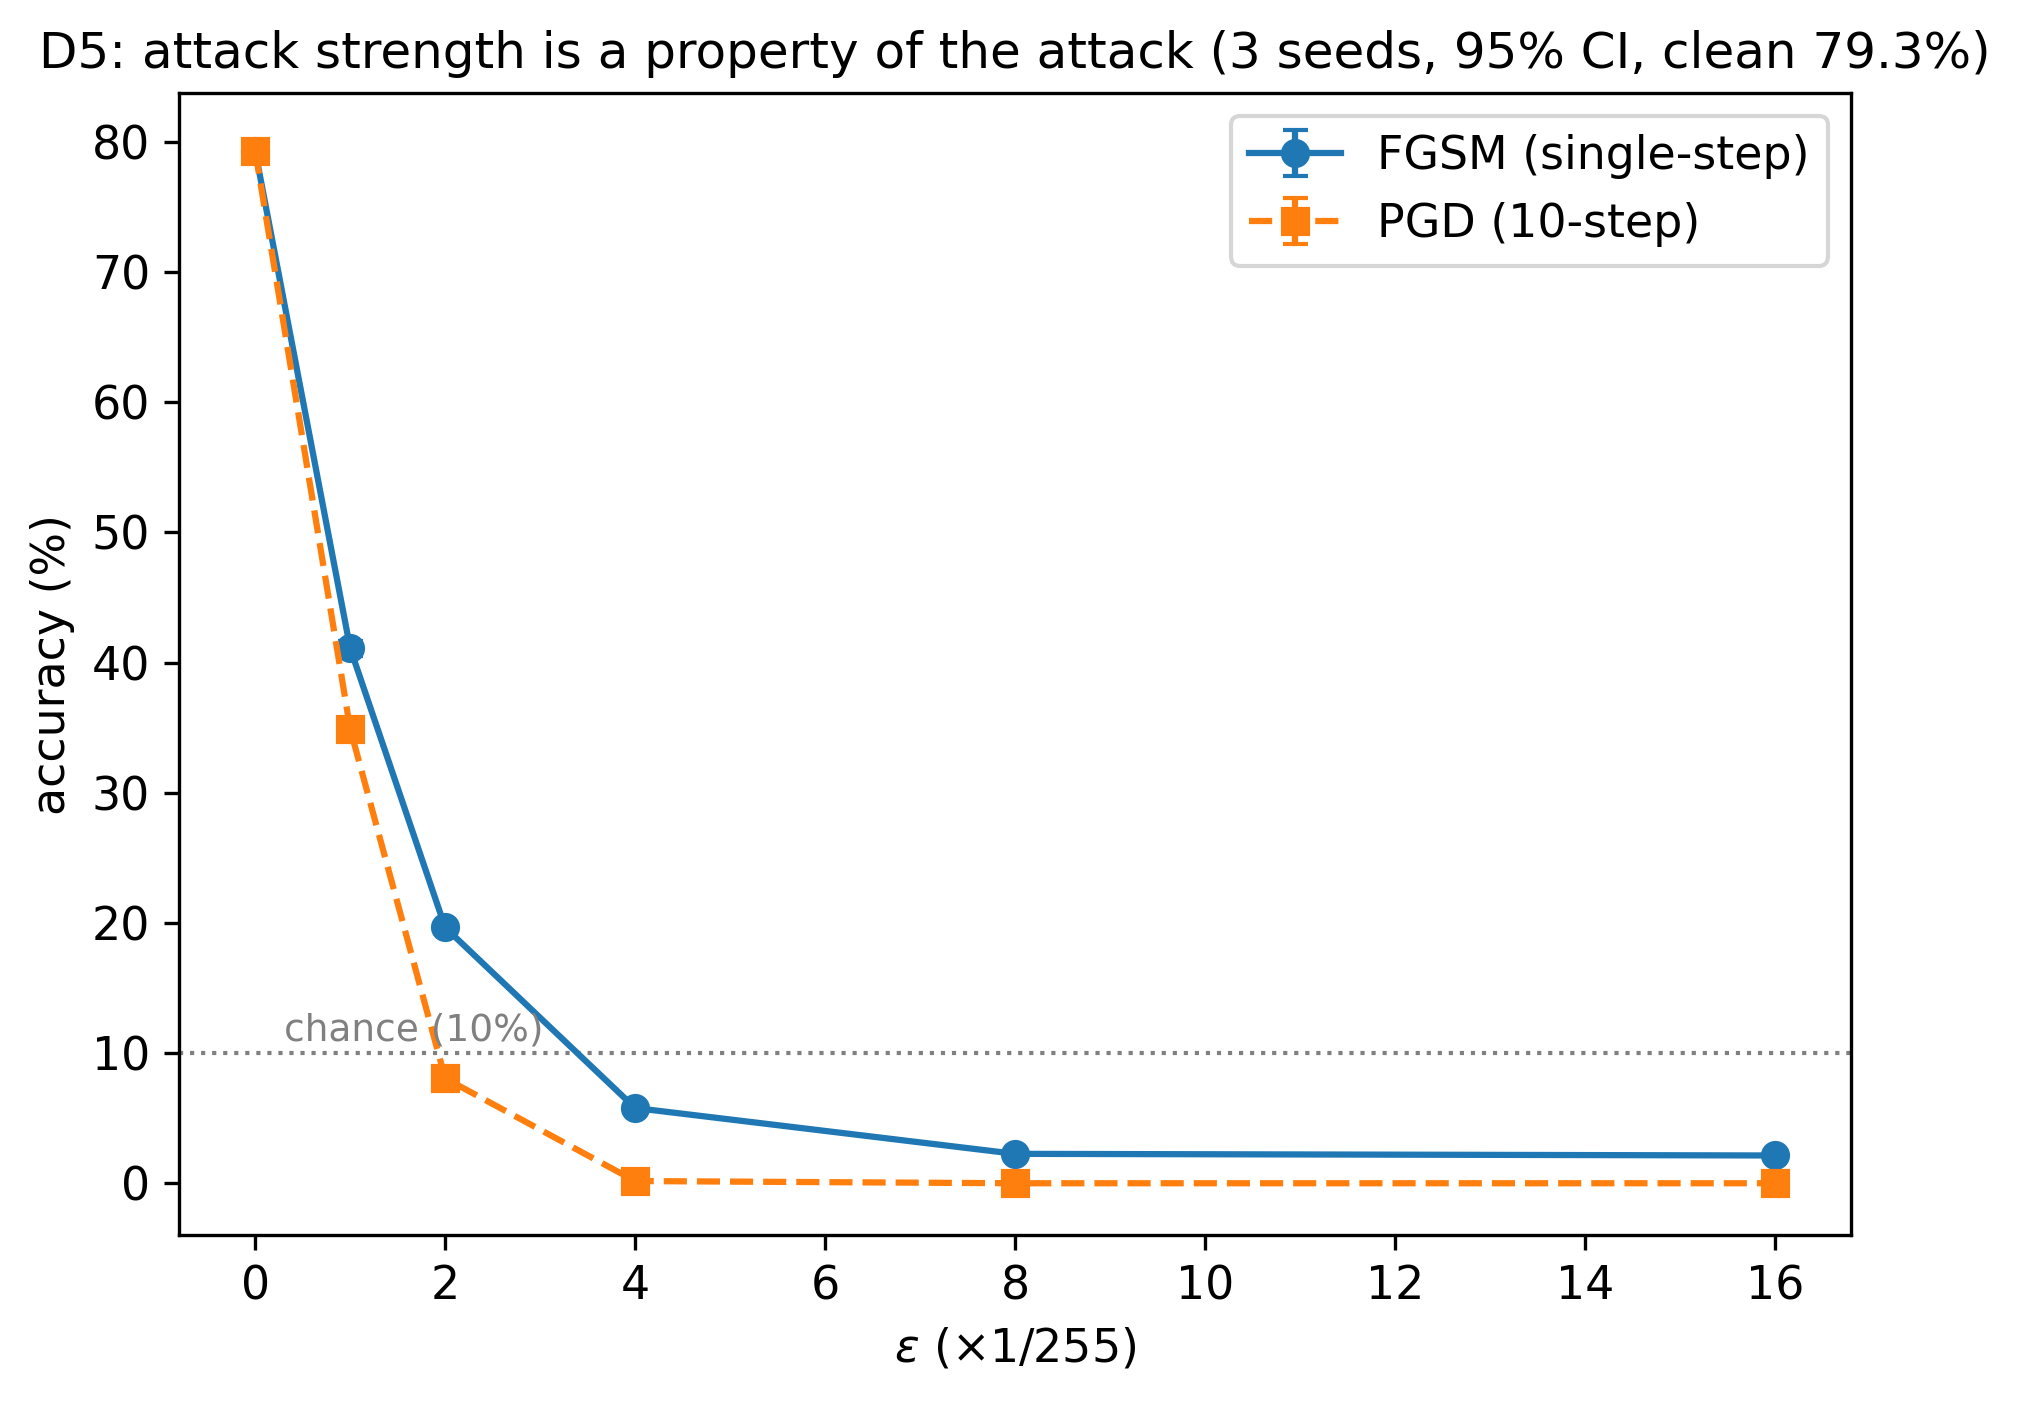

saved  /content/drive/MyDrive/AISL_data/tables/d5_attack_comparison.csv
[OK] d5_pgd {'pgd_at_eps8': 0.0, 'fgsm_nonmonotone': False, 'mcnemar_p': '0.1679', 'n_seeds': 3, 'secs': 241}


In [16]:
# ============ ADDENDUM B: PGD vs FGSM — one attack is not a measurement =====
# Full test set, three seeds, Wilson intervals, and an exact McNemar test on the
# top segment (paired: the same images under both budgets).
STAGE = 'd5_pgd'
import pandas as pd
t0 = time.time()

eps_grid = [0, 1/255, 2/255, 4/255, 8/255, 16/255]
rows = []
fgsm_correct, pgd_correct = {}, {}   # eps(int) -> pooled boolean array across seeds

for e in eps_grid:
    ek = round(e*255)
    f_seeds, p_seeds, f_pool, p_pool = [], [], [], []
    for s in SEEDS:
        torch.manual_seed(s)                 # PGD random start is reproducible per seed
        m = MODELS[s]
        fa = torchattacks.FGSM(m, eps=e) if e > 0 else None
        pa = (torchattacks.PGD(m, eps=e, alpha=max(e/4, 1/255), steps=10,
                               random_start=True) if e > 0 else None)
        fc = correctness_under_attack(m, test_ld, fa)
        pc = correctness_under_attack(m, test_ld, pa)
        f_seeds.append(fc.mean()); p_seeds.append(pc.mean())
        f_pool.append(fc); p_pool.append(pc)
    fgsm_correct[ek] = np.concatenate(f_pool)
    pgd_correct[ek]  = np.concatenate(p_pool)
    f_seeds, p_seeds = np.array(f_seeds), np.array(p_seeds)

    # Point estimate and interval MUST come from the same pooled counts, or the
    # interval can fall on the wrong side of the point and yerr goes negative.
    nf, kf = len(fgsm_correct[ek]), int(fgsm_correct[ek].sum())
    npg, kp = len(pgd_correct[ek]),  int(pgd_correct[ek].sum())
    f_hat, p_hat = kf/nf, kp/npg
    flo, fhi = wilson_pct(kf, nf)
    plo, phi = wilson_pct(kp, npg)

    rows.append({'eps_over_255': e*255, 'fgsm': f_hat, 'pgd': p_hat,
                 'fgsm_seeds': list(f_seeds), 'pgd_seeds': list(p_seeds),
                 'fgsm_ci_lo': flo, 'fgsm_ci_hi': fhi,
                 'pgd_ci_lo': plo,  'pgd_ci_hi': phi,
                 'fgsm_seed_min': f_seeds.min(), 'fgsm_seed_max': f_seeds.max(),
                 'pgd_seed_min': p_seeds.min(),  'pgd_seed_max': p_seeds.max(),
                 'n_eval_pooled': nf})
    print(f'  eps={e*255:>4.0f}/255   FGSM {f_hat*100:6.2f}% [{flo:5.2f}-{fhi:5.2f}]'
          f'   PGD {p_hat*100:6.2f}% [{plo:5.2f}-{phi:5.2f}]')

cmp = pd.DataFrame(rows)

# --- Is the FGSM curve monotone in the perturbation budget? ------------------
nonmono = [(int(cmp.eps_over_255[i-1]), int(cmp.eps_over_255[i]))
           for i in range(1, len(cmp)) if cmp.fgsm[i] > cmp.fgsm[i-1] + 1e-9]
print('FGSM non-monotone segments:', nonmono or 'none (curve is monotone)')

# Test the top segment either way, so the manuscript can state the direction and
# its significance whether or not a reversal is present.
lo_e, hi_e = (nonmono[-1] if nonmono else
              (int(cmp.eps_over_255.iloc[-2]), int(cmp.eps_over_255.iloc[-1])))
b, c, mcn_p = mcnemar(fgsm_correct[lo_e], fgsm_correct[hi_e])
mcn_txt = f'{mcn_p:.2e}' if mcn_p < 1e-3 else f'{mcn_p:.4f}'
delta   = 100*(cmp.fgsm[cmp.eps_over_255==hi_e].iloc[0]
             - cmp.fgsm[cmp.eps_over_255==lo_e].iloc[0])
print(f'McNemar on {lo_e}->{hi_e}/255 (paired, same images): b={b:,} c={c:,}  '
      f'p={mcn_txt}  delta={delta:+.2f} pts '
      f'({"accuracy RISES" if delta > 0 else "accuracy falls"} with the larger budget)')

fs_lo = np.array(cmp.loc[cmp.eps_over_255==lo_e, 'fgsm_seeds'].iloc[0])
fs_hi = np.array(cmp.loc[cmp.eps_over_255==hi_e, 'fgsm_seeds'].iloc[0])
n_rep = int((fs_hi > fs_lo).sum())
nonmono_seeds = f'{n_rep} of {len(SEEDS)}'
print(f'reversal reproduces independently in {nonmono_seeds} seeds')

def _yerr(point_pct, lo_pct, hi_pct):
    return [np.maximum(0.0, point_pct - lo_pct), np.maximum(0.0, hi_pct - point_pct)]

plt.figure()
plt.errorbar(cmp.eps_over_255, cmp.fgsm*100,
             yerr=_yerr(cmp.fgsm*100, cmp.fgsm_ci_lo, cmp.fgsm_ci_hi),
             fmt='o-', capsize=3, label='FGSM (single-step)')
plt.errorbar(cmp.eps_over_255, cmp.pgd*100,
             yerr=_yerr(cmp.pgd*100, cmp.pgd_ci_lo, cmp.pgd_ci_hi),
             fmt='s--', capsize=3, label='PGD (10-step)')
plt.axhline(10, ls=':', lw=1, color='grey')
plt.annotate('chance (10%)', xy=(0.3, 11), fontsize=9, color='grey')
plt.xlabel(r'$\epsilon$ ($\times$1/255)'); plt.ylabel('accuracy (%)'); plt.legend()
plt.title(f'D5: attack strength is a property of the attack '
          f'({len(SEEDS)} seeds, 95% CI, clean {clean_acc*100:.1f}%)')
savefig('d5_attack_comparison'); plt.show()

savetable(cmp.drop(columns=['fgsm_seeds','pgd_seeds']), 'd5_attack_comparison')
r8, r16 = cmp.loc[cmp.eps_over_255==8].iloc[0], cmp.loc[cmp.eps_over_255==16].iloc[0]
p8, f8 = float(r8.pgd), float(r8.fgsm)
record(d5_pgd_eps8=round(p8,4), d5_fgsm_minus_pgd_eps8=round(f8-p8,4),
       d5_fgsm_nonmonotone=bool(nonmono),
       d5_pgd_eps8_ci=f'{r8.pgd_ci_lo:.1f}--{r8.pgd_ci_hi:.1f}',
       d5_fgsm_eps16=round(float(r16.fgsm),4),
       d5_fgsm_eps16_ci=f'{r16.fgsm_ci_lo:.1f}--{r16.fgsm_ci_hi:.1f}',
       d5_mcnemar_p=mcn_txt, d5_nonmono_seeds=nonmono_seeds,
       d5_nonmono_segment=f'{lo_e}--{hi_e}',
       d5_top_segment_delta_pts=round(float(delta),2),
       d5_pgd_eps16=round(float(r16.pgd),4))

# Every cell of the manuscript's D5 table, formatted once here so no value is typed by hand.
def _cell(p, lo, hi):
    # Two decimals on the interval when it would otherwise print as [0.0--0.0].
    d = 2 if hi < 0.1 else 1
    return f'{p*100:.1f}\\% [{lo:.{d}f}--{hi:.{d}f}]'
for _, r in cmp.iterrows():
    ek = int(round(r.eps_over_255))
    record(**{f'd5_row_fgsm_{ek}': _cell(r.fgsm, r.fgsm_ci_lo, r.fgsm_ci_hi),
              f'd5_row_pgd_{ek}':  _cell(r.pgd,  r.pgd_ci_lo,  r.pgd_ci_hi)})
mark(STAGE, pgd_at_eps8=round(p8,4), fgsm_nonmonotone=bool(nonmono),
     mcnemar_p=mcn_txt, n_seeds=len(SEEDS), secs=round(time.time()-t0))

In [17]:
# ============ ADDENDUM C: BBQ coverage is uneven — quantify it ==============
import pandas as pd
bbq_counts = pd.read_csv(os.path.join(TABDIR, 'd34_bbq_counts.csv')).set_index('attribute')['n']
s = bbq_counts.sort_values(ascending=False)
top2  = float(s.iloc[:2].sum()/s.sum()*100)
ratio = float(s.iloc[0]/s.iloc[-1])
print(f'top-2 categories = {top2:.1f}% of corpus ({", ".join(s.index[:2])})')
print(f'largest:smallest = {ratio:.1f}:1  ({s.index[0]} vs {s.index[-1]})')
record(bbq_top_two_share=round(top2,1), bbq_imbalance=round(ratio,1),
       bbq_largest=str(s.index[0]), bbq_smallest=str(s.index[-1]))

top-2 categories = 46.4% of corpus (raceXGender, raceXSes)
largest:smallest = 18.5:1  (raceXGender vs sexualOrientation)


SMS corpus: n=5,574 | spam=747 (13.4%)
  t=0.3: precision  93.2%  recall  92.0%  F1  92.6%  false alarms 15  missed scams 18 of 224
  t=0.5: precision  96.6%  recall  89.3%  F1  92.8%  false alarms 7  missed scams 24 of 224
  t=0.7: precision  98.9%  recall  83.9%  F1  90.8%  false alarms 2  missed scams 36 of 224
average precision = 0.976 | best-F1 threshold = 0.55 (F1 93.2%)
saved  /content/drive/MyDrive/AISL_data/figures/d3_sms_threshold.jpg  (296 KB)


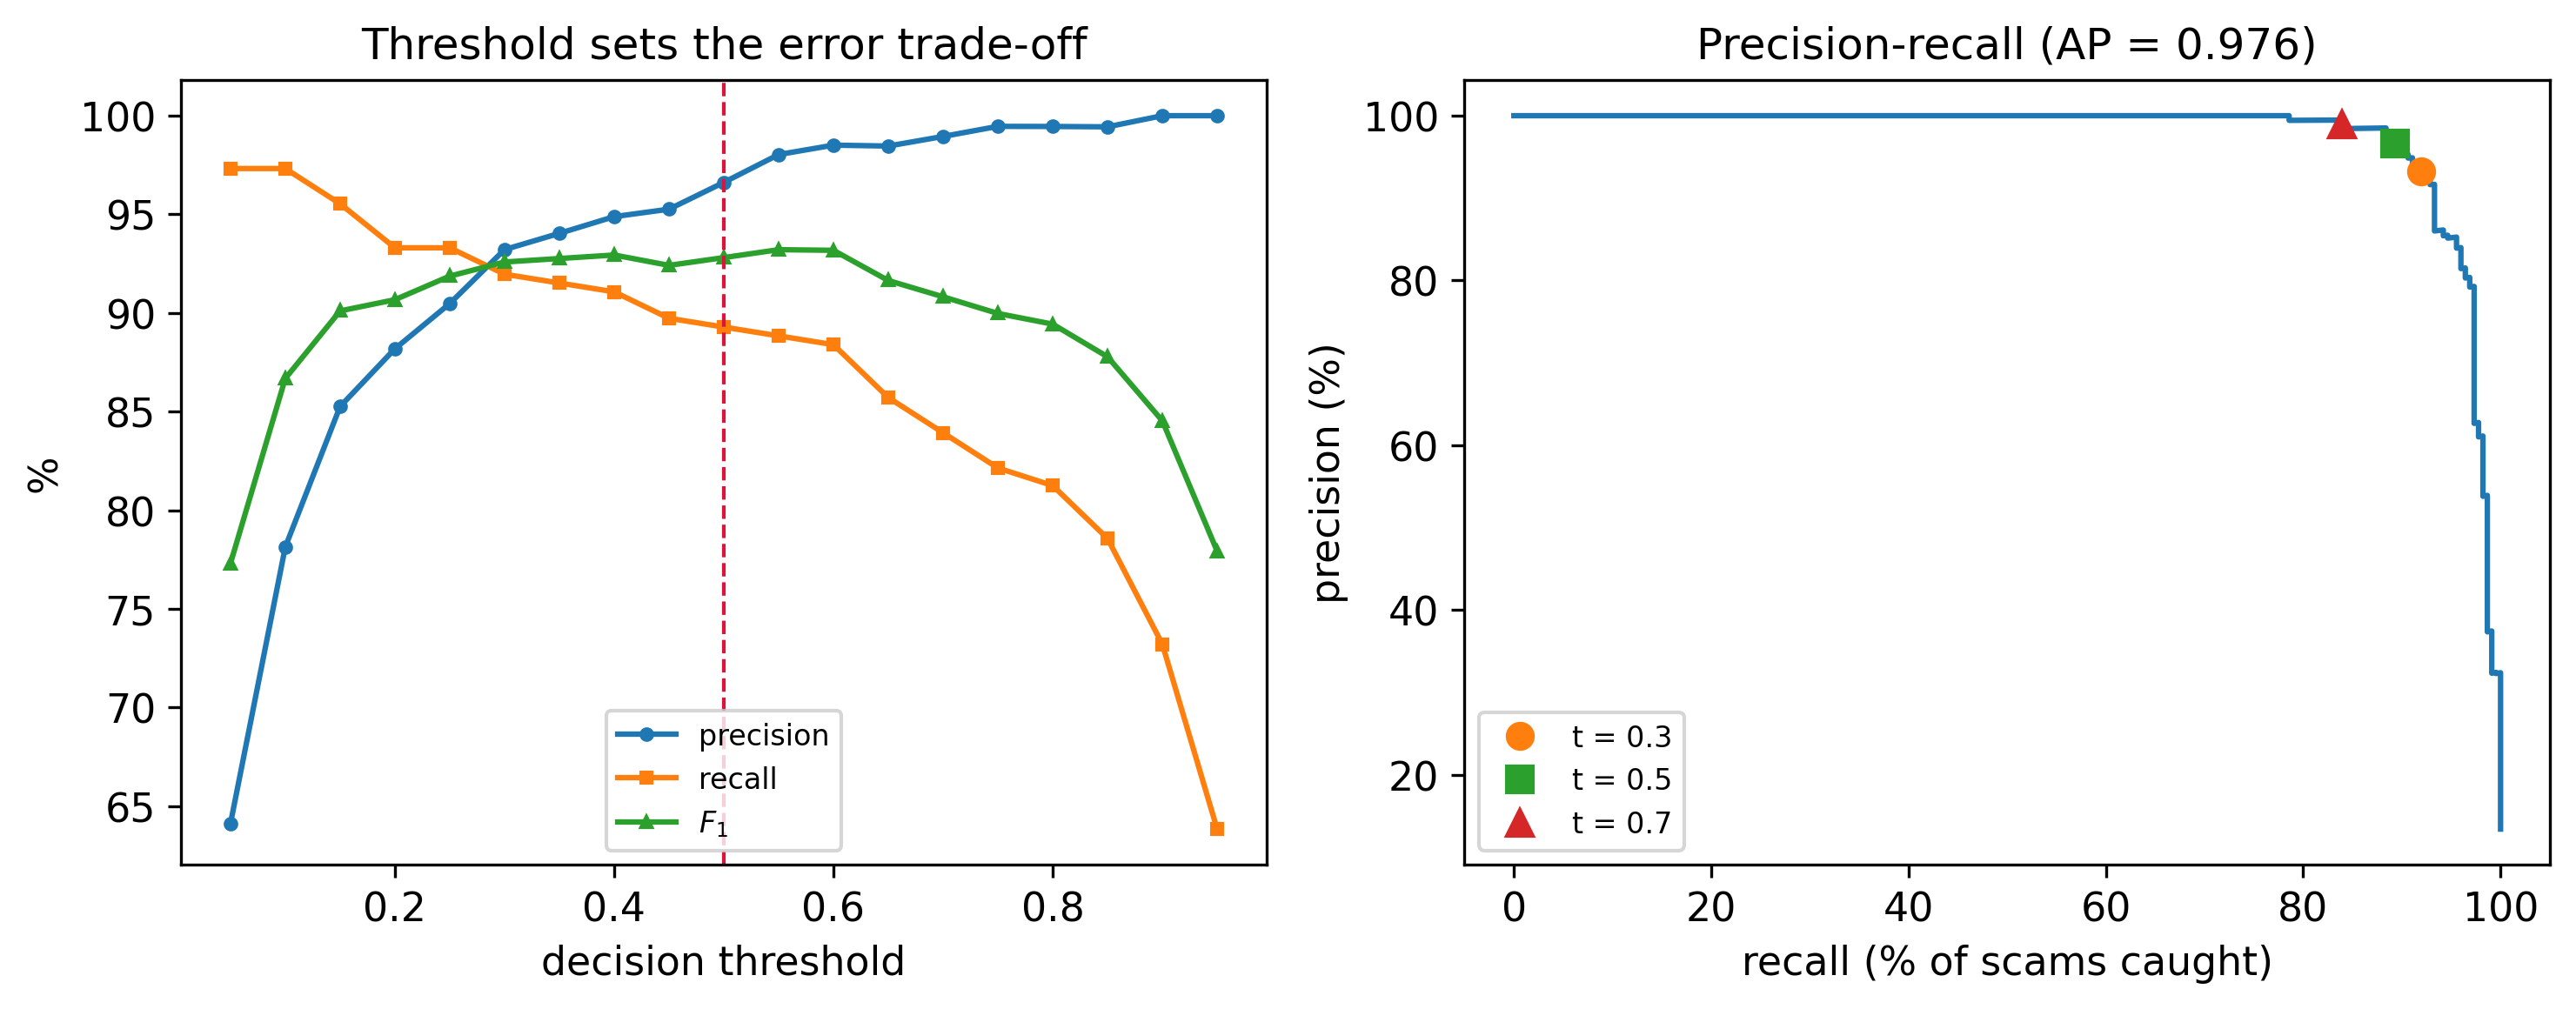

saved  /content/drive/MyDrive/AISL_data/tables/d3_sms_threshold.csv
[OK] d3_sms {'n': 5574, 'ap': 0.976, 'best_t': 0.55}
ATP W142.sav: n=10,133 | relevant items=16 | weight=WEIGHT_W142
ATP W152.sav: n=5,410 | relevant items=60 | weight=WEIGHT_W152
ATP W168.sav: n=9,397 | relevant items=39 | weight=WEIGHT_W168
saved  /content/drive/MyDrive/AISL_data/tables/pew_item_inventory.csv
        file                variable                                                        label  n_valid
ATP W142.sav              USEAI_W142 USEAI_W142. Just your impression, how often do you intera...     9994
ATP W142.sav          GENAICRED_W142 GENAICRED_W142. Overall, which of the following statement...    10098
ATP W142.sav       AICOPYRGHT_a_W142 AICOPYRGHT_a_W142. Provide information that matches what ...     5026
ATP W142.sav       AICOPYRGHT_b_W142 AICOPYRGHT_b_W142. Imitate the writing style of a famous ...     5023
ATP W142.sav       AICOPYRGHT_c_W142 AICOPYRGHT_c_W142. Produce images in the style 

In [18]:
# ============ ADDENDUM D: D3 scam-text thresholds + Tier 1 survey evidence ==========
# Runs before the EMITTER, which preserves this cell's macro block.
# Needs cells 0-3 (Drive, seed, status, plotting helpers).
#
# Inputs (all under MyDrive/AISL_data/microdata/):
#   sms/   UCI SMS Spam Collection   -- downloaded automatically if absent
#   pew/   Pew ATP waves 168, 152, 142 (.sav) -- you download (free Pew account)
#   rand/  RAND AEP survey file + codebook -- you download (free RSP registration)
# A missing input is reported as a skipped stage; nothing is ever simulated.
import os, re, sys, glob, zipfile, subprocess, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt

EXT_DIR = {k: os.path.join(DIRS['data'], k) for k in ('sms', 'pew', 'rand')}
for _p in EXT_DIR.values():
    os.makedirs(_p, exist_ok=True)
EXT = {}                                   # macro name -> value, written at the end

def _wshare(values, weights):
    """Weighted share (%) of each category; NaN / 'No answer' / 'Refused' dropped."""
    s = pd.DataFrame({'v': values, 'w': weights}).dropna()
    s = s[~s.v.astype(str).str.contains(r'(?i)no answer|refused|^\s*$', regex=True)]
    if s.empty:
        return pd.Series(dtype=float), 0
    tot = s.groupby('v', observed=True).w.sum()
    return (100 * tot / tot.sum()).sort_values(ascending=False), int(len(s))

def _weight_col(df):
    cands = [c for c in df.columns if re.match(r'(?i)^weight', c)] or \
            [c for c in df.columns if re.search(r'(?i)weight|wgt|wt$', c)]
    return cands[0] if cands else None

def _read_survey(path):
    """Returns (dataframe with value labels applied, {var: label})."""
    ext = os.path.splitext(path)[1].lower()
    if ext in ('.sav', '.dta', '.por'):
        try:
            import pyreadstat
        except ImportError:
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pyreadstat'], check=True)
            import pyreadstat
        reader = {'.sav': pyreadstat.read_sav, '.por': pyreadstat.read_por,
                  '.dta': pyreadstat.read_dta}[ext]
        df, meta = reader(path, apply_value_formats=True)
        return df, dict(meta.column_names_to_labels)
    if ext == '.csv':
        df = pd.read_csv(path, low_memory=False)
        return df, {c: '' for c in df.columns}
    if ext in ('.xlsx', '.xls'):
        df = pd.read_excel(path)
        return df, {c: '' for c in df.columns}
    raise ValueError(f'unsupported survey format: {path}')

# =====================================================================================
# D3: SMS Spam Collection -- the label is a threshold decision on real scam text
# =====================================================================================
STAGE = 'd3_sms'
try:
    from sklearn.feature_extraction.text import CountVectorizer
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import precision_recall_curve, average_precision_score

    sms_path = os.path.join(EXT_DIR['sms'], 'SMSSpamCollection')
    if not os.path.exists(sms_path):
        zp = os.path.join(EXT_DIR['sms'], 'sms_spam_collection.zip')
        if not os.path.exists(zp):
            urllib.request.urlretrieve(
                'https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip', zp)
        with zipfile.ZipFile(zp) as z:
            z.extract('SMSSpamCollection', EXT_DIR['sms'])
    with open(sms_path, encoding='utf-8', errors='replace') as f:
        rows = [ln.rstrip('\n').split('\t', 1) for ln in f if '\t' in ln]
    sms = pd.DataFrame(rows, columns=['label', 'text'])
    sms = sms[sms.label.isin(['ham', 'spam'])].reset_index(drop=True)
    y = (sms.label == 'spam').astype(int).values
    print(f'SMS corpus: n={len(sms):,} | spam={y.sum():,} ({100*y.mean():.1f}%)')

    # Multi-hot bag of words over a ~500-word vocabulary: the same input form as the
    # platform's scam classifier, so the trade-off shown is the one learners face.
    Xtr_t, Xte_t, ytr, yte = train_test_split(sms.text, y, test_size=0.30,
                                              stratify=y, random_state=SEED)
    vec = CountVectorizer(lowercase=True, binary=True, max_features=500)
    Xtr, Xte = vec.fit_transform(Xtr_t), vec.transform(Xte_t)
    clf = LogisticRegression(max_iter=2000, random_state=SEED).fit(Xtr, ytr)
    p = clf.predict_proba(Xte)[:, 1]
    ap = float(average_precision_score(yte, p))

    def _at(t):
        pred = p >= t
        tp = int((pred & (yte == 1)).sum()); fp = int((pred & (yte == 0)).sum())
        fn = int((~pred & (yte == 1)).sum())
        prec = tp / (tp + fp) if tp + fp else float('nan')
        rec = tp / (tp + fn) if tp + fn else float('nan')
        f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
        return prec, rec, f1, fp, fn

    grid = np.round(np.arange(0.05, 0.951, 0.05), 2)
    tab = pd.DataFrame([dict(zip(['threshold', 'precision', 'recall', 'f1',
                                  'false_pos', 'missed_spam'], (t, *_at(t)))) for t in grid])
    best = tab.loc[tab.f1.idxmax()]
    pts = {t: _at(t) for t in (0.3, 0.5, 0.7)}
    n_spam_te = int(yte.sum())
    for t, (pr, rc, f1, fp, fn) in pts.items():
        print(f'  t={t:.1f}: precision {pr*100:5.1f}%  recall {rc*100:5.1f}%  '
              f'F1 {f1*100:5.1f}%  false alarms {fp}  missed scams {fn} of {n_spam_te}')
    print(f'average precision = {ap:.3f} | best-F1 threshold = {best.threshold:.2f} '
          f'(F1 {best.f1*100:.1f}%)')

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
    a1.plot(tab.threshold, tab.precision * 100, 'o-', ms=3, label='precision')
    a1.plot(tab.threshold, tab.recall * 100, 's-', ms=3, label='recall')
    a1.plot(tab.threshold, tab.f1 * 100, '^-', ms=3, label='$F_1$')
    a1.axvline(0.5, ls='--', lw=1, color='crimson')
    a1.set_xlabel('decision threshold'); a1.set_ylabel('%'); a1.legend(fontsize=8)
    a1.set_title('Threshold sets the error trade-off')
    prc, rcc, _ = precision_recall_curve(yte, p)
    a2.plot(rcc * 100, prc * 100, lw=1.5)
    for t, mk in zip((0.3, 0.5, 0.7), ('o', 's', '^')):
        a2.plot(pts[t][1] * 100, pts[t][0] * 100, mk, ms=7, label=f't = {t}')
    a2.set_xlabel('recall (% of scams caught)'); a2.set_ylabel('precision (%)')
    a2.set_title(f'Precision-recall (AP = {ap:.3f})'); a2.legend(fontsize=8)
    savefig('d3_sms_threshold'); plt.show()
    savetable(tab, 'd3_sms_threshold')

    loc = {
        'dThreeSMSN': f'{len(sms):,}', 'dThreeSMSSpamPct': f'{100*y.mean():.1f}',
        'dThreeSMSTestN': f'{len(yte):,}', 'dThreeSMSTestSpam': f'{n_spam_te:,}',
        'dThreeSMSAP': f'{ap:.3f}', 'dThreeSMSVocab': f'{len(vec.vocabulary_)}',
        'dThreeSMSBestT': f'{best.threshold:.2f}', 'dThreeSMSBestFOne': f'{best.f1*100:.1f}\\%',
        'statusSMS': 'Computed'}
    for t, nm in ((0.3, 'Three'), (0.5, 'Five'), (0.7, 'Seven')):
        pr, rc, f1, fp, fn = pts[t]
        loc[f'dThreeSMSPrec{nm}'] = f'{pr*100:.1f}\\%'
        loc[f'dThreeSMSRec{nm}'] = f'{rc*100:.1f}\\%'
        loc[f'dThreeSMSFP{nm}'] = str(fp)
        loc[f'dThreeSMSMissed{nm}'] = str(fn)
    EXT.update(loc)
    record(d3sms_n=len(sms), d3sms_ap=round(ap, 4), d3sms_best_t=float(best.threshold))
    mark(STAGE, n=len(sms), ap=round(ap, 3), best_t=float(best.threshold))
except Exception as e:
    EXT['statusSMS'] = 'not executed'
    mark(STAGE, 'failed', error=repr(e)[:200]); print('SMS stage failed:', e)

# =====================================================================================
# Tier 1: survey item inventories (Pew American Trends Panel waves, RAND AEP).
# Discovery only: every relevant item with its weighted distribution, so the
# item-to-dimension map is built from the real codebooks. No dimension scores are
# produced until that map exists, and nothing is filled in for a missing file.
# =====================================================================================
TOPIC_RX = (r'\bAI\b|artificial intelligence|generative|chatgpt|chatbot|large language|'
            r'scam|fraud|phish|hack|identity theft|privacy|personal (data|information)|'
            r'misinformation|deepfake|cheat')

def _inventory(stage, folder, tag):
    files = sorted(f for f in glob.glob(os.path.join(folder, '**', '*'), recursive=True)
                   if f.lower().endswith(('.sav', '.dta', '.por', '.csv', '.xlsx')))
    if not files:
        EXT[f'status{tag}'] = 'not executed'
        mark(stage, 'skipped', blockers=f'no survey file in {folder}')
        return
    try:
        inv, n_resp = [], 0
        for path in files:
            df, lab = _read_survey(path)
            n_resp += len(df)
            wcol = _weight_col(df)
            w = df[wcol].astype(float) if wcol else pd.Series(1.0, index=df.index)
            hits = [c for c in df.columns if c != wcol and
                    (re.search(TOPIC_RX, lab.get(c) or '', re.I) or re.search(TOPIC_RX, c, re.I))]
            print(f'{os.path.basename(path)}: n={len(df):,} | relevant items={len(hits)} '
                  f'| weight={wcol or "none (unweighted)"}')
            for c in hits:
                sh, n = _wshare(df[c], w)
                inv.append({'file': os.path.basename(path), 'variable': c,
                            'label': lab.get(c, ''), 'n_valid': n, 'weighted': bool(wcol),
                            'distribution': '; '.join(f'{k}: {v:.1f}%' for k, v in sh.head(6).items())})
        inv = pd.DataFrame(inv)
        name = f'{tag.lower()}_item_inventory'
        savetable(inv, name)
        if len(inv):
            print(inv[['file', 'variable', 'label', 'n_valid']]
                  .to_string(index=False, max_colwidth=60))
        else:
            print('no relevant items found -- check the codebook')
        EXT.update({f'{tag.lower()}N': f'{n_resp:,}', f'{tag.lower()}Items': str(len(inv)),
                    f'status{tag}': 'Inventoried'})
        mark(stage, files=len(files), n=n_resp, items=len(inv))
        print(f'NEXT: send tables/{name}.csv and the codebook(s) to map items to dimensions.\n')
    except Exception as e:
        EXT[f'status{tag}'] = 'failed'
        mark(stage, 'failed', error=repr(e)[:200]); print(f'{stage} failed:', e)

_inventory('tier1_pew_inventory', EXT_DIR['pew'], 'Pew')
_inventory('tier1_rand_inventory', EXT_DIR['rand'], 'RAND')

# =====================================================================================
# Append this addendum's macros to tables/aisl_results.tex (replacing any earlier copy).
# \def is used so the block works whether or not the article already declares them.
# =====================================================================================
res_tex = os.path.join(TABDIR, 'aisl_results.tex')
txt = open(res_tex).read() if os.path.exists(res_tex) else ''
txt = re.sub(r'% BEGIN ADDENDUM D.*?% END ADDENDUM D\n?', '', txt, flags=re.S)
block = ['% BEGIN ADDENDUM D'] + [f'\\def\\{k}{{{v}}}' for k, v in EXT.items()] + ['% END ADDENDUM D']
with open(res_tex, 'w') as f:
    f.write(txt.rstrip('\n') + '\n\n' + '\n'.join(block) + '\n')
print('\nappended to', res_tex); print('\n'.join(block))


survey files found under /content/drive/MyDrive/AISL_data
    microdata/ATP W152.sav
    microdata/pew/ATP W142.sav
    microdata/pew/ATP W152.sav
    microdata/pew/ATP W168.sav
    microdata/rand (1)/GAL1025T_ATP_Portal.dta

[D1] AI_POLICY (RAND ATP/Gallup (Fall 2025)) n=1,987 n_eff=1,533  ->  34.5%  Teachers: school has an AI policy
    counted: ['Yes']
       39.7%  No
       34.5%  Yes
       25.8%  I don't know

[D1] AI_POLICY (RAND ATP/Gallup (Fall 2025)) n=1,987 n_eff=1,533  ->  25.8%  Teachers: do not know if school has an AI policy
    counted: ["I don't know"]
       39.7%  No
       34.5%  Yes
       25.8%  I don't know

[D1] AI_POLICY_CLEAR (RAND ATP/Gallup (Fall 2025)) n=711 n_eff=555  ->  36.2%  Teachers: policy very or extremely clear (of those with one)
    counted: ['Extremely clear', 'Very clear']
       49.7%  Somewhat clear
       25.5%  Very clear
       12.4%  Not too clear
       10.7%  Extremely clear
        1.8%  Not clear at all

[D1] AI_PACE_SCHOOL (RAND ATP

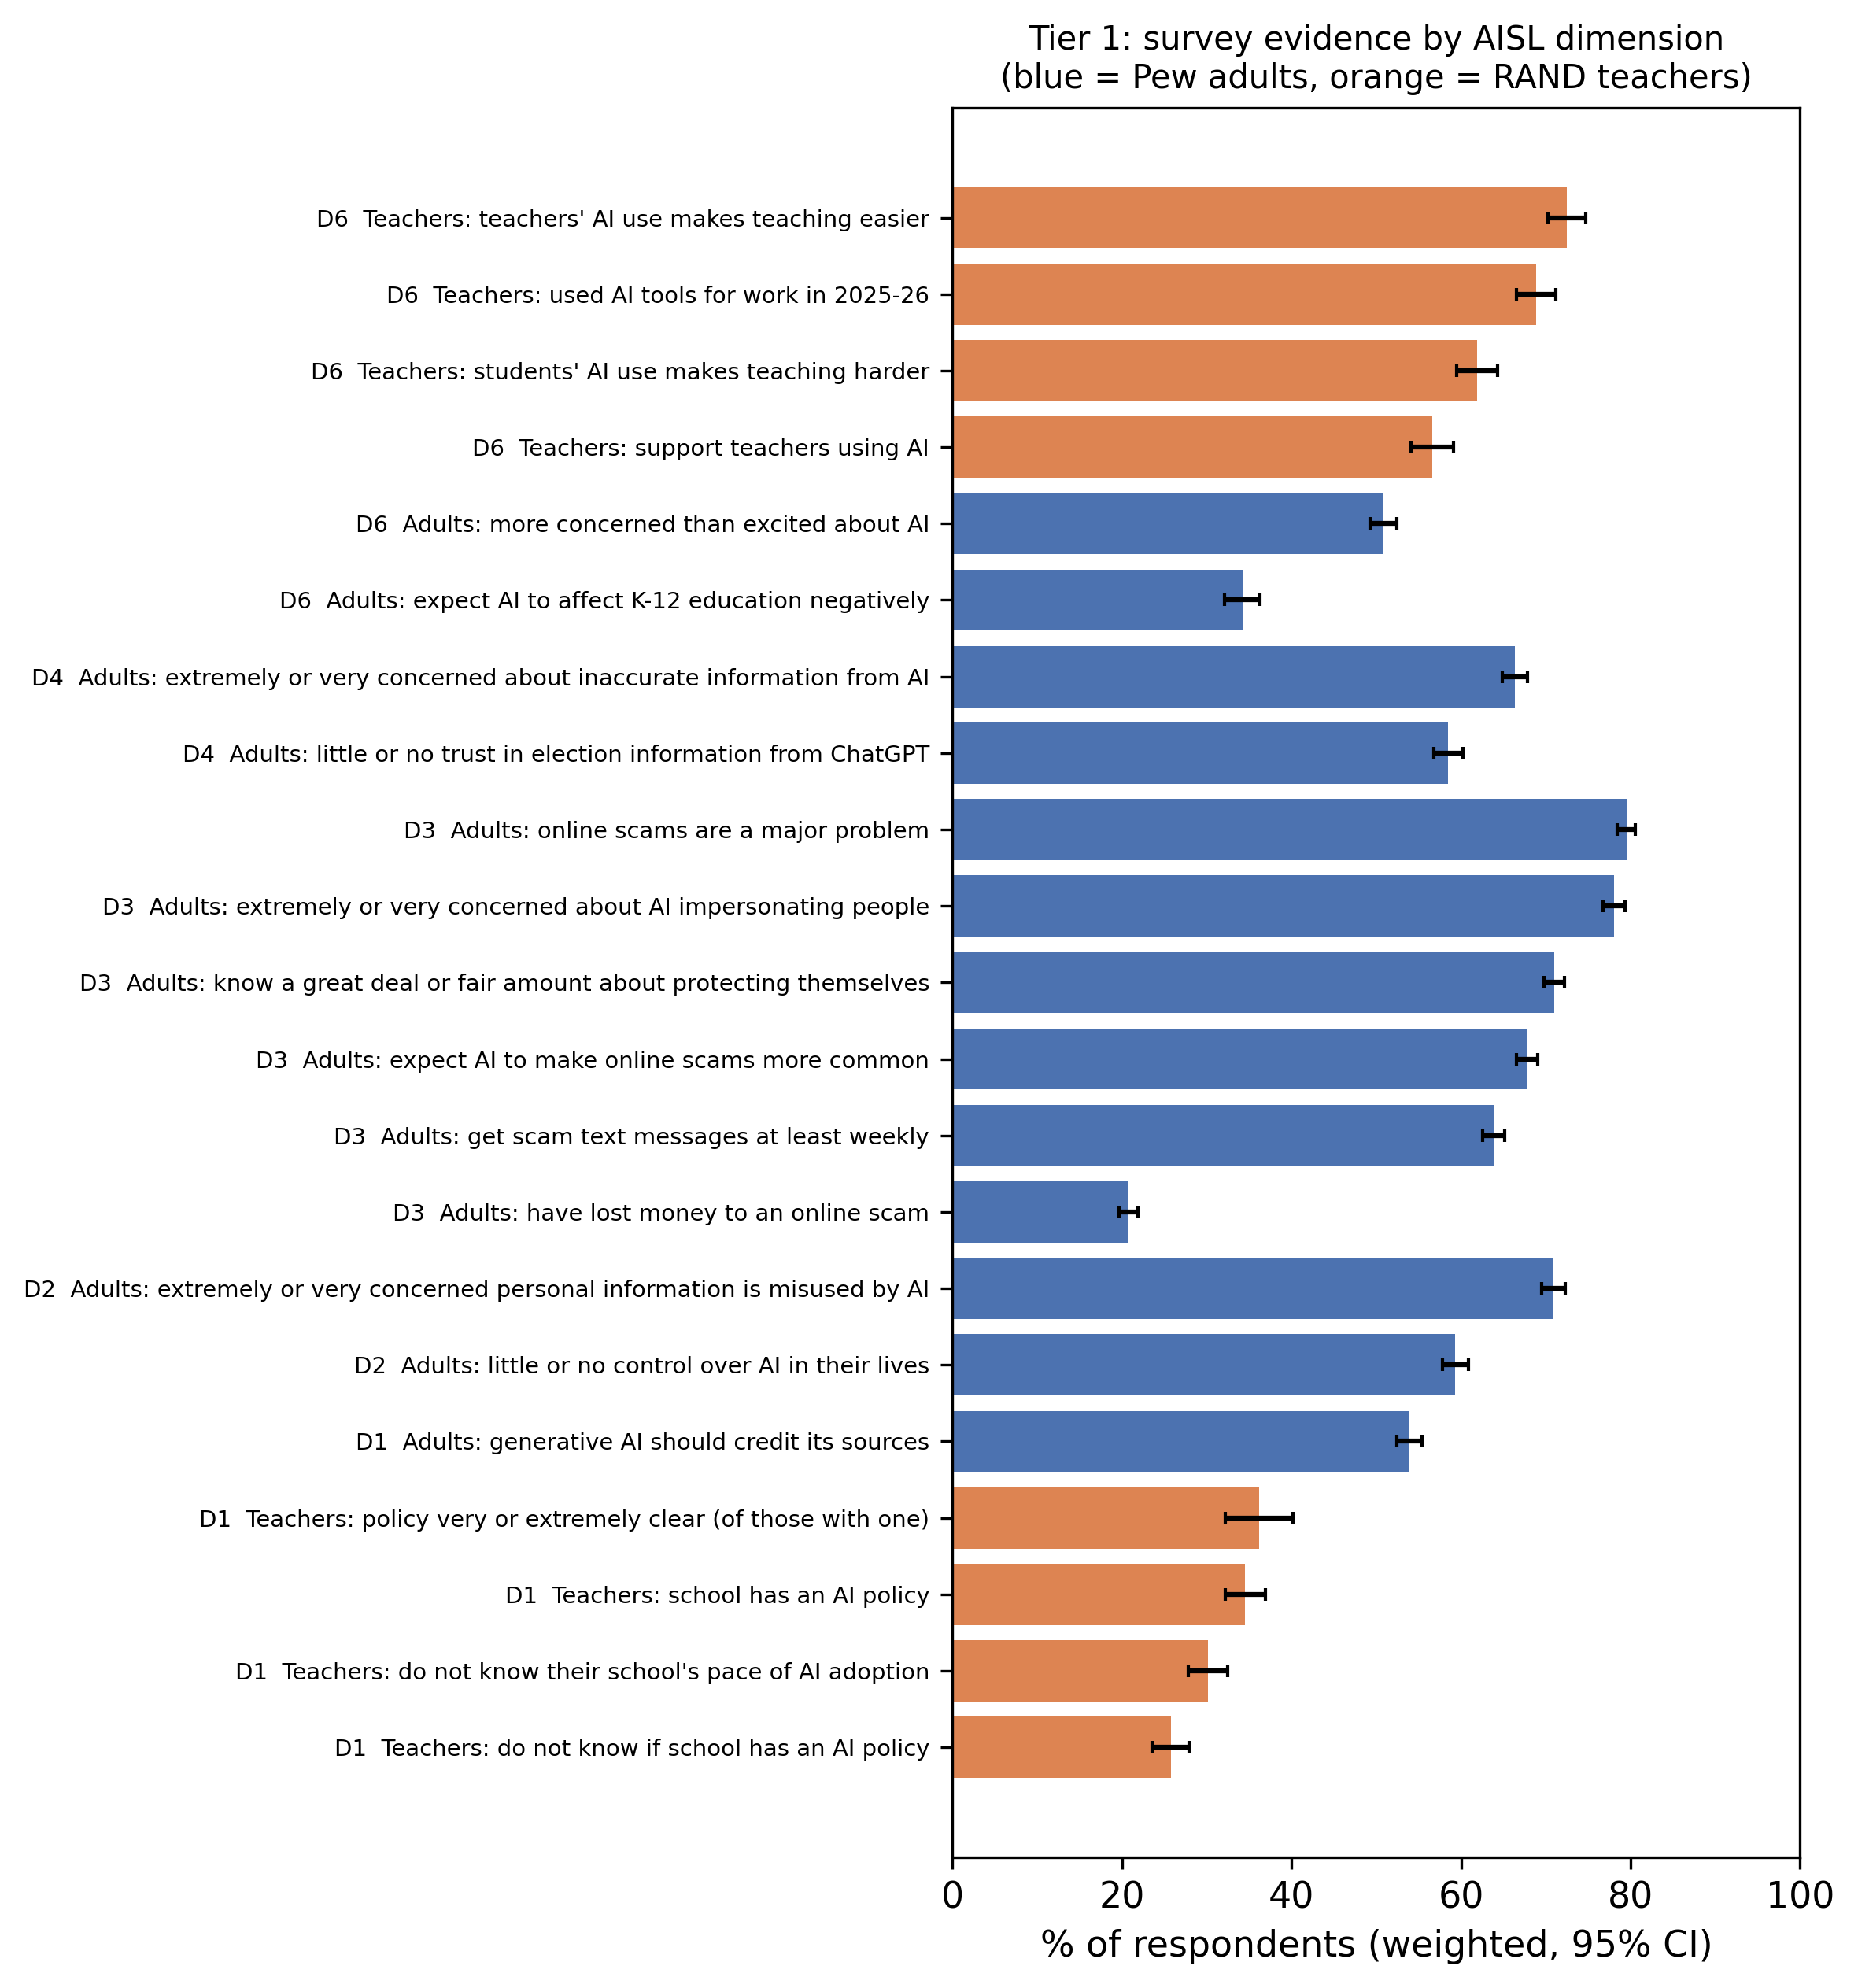

[OK] tier1_mapped {'items': 21, 'sources': 4}

appended to /content/drive/MyDrive/AISL_data/tables/aisl_results.tex


In [19]:
# ============ ADDENDUM E: Tier 1 mapped survey evidence (Pew ATP + RAND/Gallup ATP) =========
# Run after Addendum D (uses its survey readers). Reads every survey file in microdata/pew and microdata/rand,
# computes the weighted share giving the stated response for each mapped item, with
# a 95% CI from the Kish effective sample size, and appends macros to aisl_results.tex.
# Each item prints its full weighted distribution and the categories counted, so the
# headline share can be checked against the questionnaire. Nothing is imputed.
import os, re, glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt

# (dimension, macro, item, short description, regex for the counted response categories)
SPEC = [
 ('D1', 'tOnePolicyYes',     'AI_POLICY',            'Teachers: school has an AI policy',                 r'^yes'),
 ('D1', 'tOnePolicyDK',      'AI_POLICY',            'Teachers: do not know if school has an AI policy',  r"don.?t know"),
 ('D1', 'tOnePolicyClear',   'AI_POLICY_CLEAR',      'Teachers: policy very or extremely clear (of those with one)', r'^(very|extremely) clear'),
 ('D1', 'tOnePaceDK',        'AI_PACE_SCHOOL',       "Teachers: do not know their school's pace of AI adoption", r"don.?t know"),
 ('D1', 'tOneCredit',        'GENAICRED_W142',       'Adults: generative AI should credit its sources',   r'^(?!.*\bnot\b).*(should|credit)'),
 ('D2', 'tTwoPersInfo',      'AICONCERN_c_W152',     'Adults: extremely or very concerned personal information is misused by AI', r'^(extremely|very) concerned'),
 ('D2', 'tTwoLowControl',    'AICONTROL1_W152',      'Adults: little or no control over AI in their lives', r'not too much|not much|none|no control|very little'),
 ('D3', 'tThreeScamProb',    'OSCAM_PROB_W168',      'Adults: online scams are a major problem',          r'major'),
 ('D3', 'tThreeScamText',    'OSCAM_PHISH_c_W168',   'Adults: get scam text messages at least weekly',    r'day|week'),
 ('D3', 'tThreeLostMoney',   'OSCAM_MONEY1_W168',    'Adults: have lost money to an online scam',         r'^yes'),
 ('D3', 'tThreeKnowLot',     'OSCAM_KNOW_W168',      'Adults: know a great deal or fair amount about protecting themselves', r'^a (great deal|fair amount)'),
 ('D3', 'tThreeScamAI',      'OSCAM_AI_W168',        'Adults: expect AI to make online scams more common', r'more|worse|increase'),
 ('D3', 'tThreeImperson',    'AICONCERN_b_W152',     'Adults: extremely or very concerned about AI impersonating people', r'^(extremely|very) concerned'),
 ('D4', 'tFourInaccurate',   'AICONCERN_d_W152',     'Adults: extremely or very concerned about inaccurate information from AI', r'^(extremely|very) concerned'),
 ('D4', 'tFourTrustGPT',     'GPTPOL2_W142',         'Adults: little or no trust in election information from ChatGPT', r'^(not too much|none at all)'),
 ('D6', 'tSixConcerned',     'CNCEXC_W152',          'Adults: more concerned than excited about AI',      r'concerned than excited'),
 ('D6', 'tSixKTwelveNeg',    'AIFUTRIMPCT_b_W152',   'Adults: expect AI to affect K-12 education negatively', r'^(very|somewhat) negative'),
 ('D6', 'tSixTeachUse',      'AI_USER',              'Teachers: used AI tools for work in 2025-26',       r'^yes'),
 ('D6', 'tSixTeachSupport',  'AI_SUPPORT1',          'Teachers: support teachers using AI',               r'^(strongly|somewhat) support'),
 ('D6', 'tSixStudHarder',    'AI_EASY_DIFF_STUDENT', "Teachers: students' AI use makes teaching harder",  r'harder'),
 ('D6', 'tSixTeachEasier',   'AI_EASY_DIFF_TEACHER', "Teachers: teachers' AI use makes teaching easier",  r'easier'),
]
SOURCE_NAME = {'W142': 'Pew ATP W142 (Feb 2024)', 'W152': 'Pew ATP W152 (Aug 2024)',
               'W168': 'Pew ATP W168 (Apr 2025)', 'GAL1025T': 'RAND ATP/Gallup (Fall 2025)',
               'AIR0424T': 'RAND ATP AIRS (Spring 2024)'}

def _src(path, var):
    for k, v in SOURCE_NAME.items():
        if k.lower() in os.path.basename(path).lower() or var.upper().endswith('_' + k):
            return v
    return os.path.basename(path)

# Load every survey file once; index columns case-insensitively.
_root = os.path.dirname(DIRS['data'])
files = sorted(f for f in glob.glob(os.path.join(_root, '**', '*'), recursive=True)
               if f.lower().endswith(('.sav', '.dta', '.por')) and '/cache/' not in f)
print('survey files found under', _root)
for f in files:
    print('   ', os.path.relpath(f, _root))
if not any(re.search(r'GAL1025T', f, re.I) for f in files):
    print('!! no RAND GAL1025T .dta under AISL_data -- the teacher (RAND) items will be skipped')
loaded = []
for f in files:
    df_, lab_ = _read_survey(f)
    loaded.append((f, df_, lab_, _weight_col(df_), {c.upper(): c for c in df_.columns}))

STAGE = 'tier1_mapped'
rows, E = [], {}
for dim, mac, var, desc, rx in SPEC:
    hit = next(((f, d, l, wc, cm[var.upper()]) for f, d, l, wc, cm in loaded if var.upper() in cm), None)
    if hit is None:
        print(f'[--] {var}: not in any loaded file (skipped)'); continue
    f, d, l, wc, col = hit
    w = d[wc].astype(float) if wc else pd.Series(1.0, index=d.index)
    sub = pd.DataFrame({'v': d[col], 'w': w}).dropna()
    sub = sub[~sub.v.astype(str).str.contains(r'(?i)no answer|refused|^\s*$', regex=True)]
    if sub.empty:
        print(f'[--] {var}: no valid responses'); continue
    tot = sub.groupby('v', observed=True).w.sum(); dist = 100 * tot / tot.sum()
    counted = [k for k in dist.index if re.search(rx, str(k), re.I)]
    share = float(dist[counted].sum())
    n = len(sub); n_eff = sub.w.sum() ** 2 / (sub.w ** 2).sum()
    p = share / 100; half = 1.96 * np.sqrt(p * (1 - p) / n_eff) * 100
    rows.append({'dimension': dim, 'source': _src(f, col), 'item': col, 'description': desc,
                 'share_pct': share, 'ci_lo': max(0, share - half), 'ci_hi': min(100, share + half),
                 'n': n, 'n_eff': round(n_eff), 'weighted': bool(wc),
                 'counted': ' | '.join(map(str, counted))})
    print(f'\n[{dim}] {col} ({_src(f, col)}) n={n:,} n_eff={n_eff:,.0f}  ->  {share:.1f}%  {desc}')
    print('    counted:', counted or 'NOTHING MATCHED -- check regex against the categories below')
    for k, v in dist.sort_values(ascending=False).items():
        print(f'      {v:5.1f}%  {k}')
    E[mac] = f'{share:.1f}\\%'
    E[mac + 'N'] = f'{n:,}'

res = pd.DataFrame(rows)
if len(res):
    savetable(res, 'tier1_mapped_results')
    res = res.sort_values(['dimension', 'share_pct'])
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(res) + 1.2))
    ypos = np.arange(len(res))
    ax.barh(ypos, res.share_pct, xerr=[res.share_pct - res.ci_lo, res.ci_hi - res.share_pct],
            capsize=2, color=['#4c72b0' if s.startswith('Pew') else '#dd8452' for s in res.source])
    ax.set_yticks(ypos, [f'{d}  {t}' for d, t in zip(res.dimension, res.description)], fontsize=7)
    ax.set_xlim(0, 100); ax.set_xlabel('% of respondents (weighted, 95% CI)')
    ax.set_title('Tier 1: survey evidence by AISL dimension\n(blue = Pew adults, orange = RAND teachers)',
                 fontsize=10)
    savefig('tier1_survey_evidence'); plt.show()
    srcs = sorted(res.source.unique())
    E.update({'statusTierOne': 'Computed', 'tierOneItems': str(len(res)), 'tierOneSources': str(len(srcs)),
              'tierOneTeacherN': f'{int(res[res.source.str.startswith("RAND")].n.max()):,}'
                                 if (res.source.str.startswith('RAND')).any() else '0'})
    record(tier1_mapped_items=int(len(res)))
    mark(STAGE, items=int(len(res)), sources=len(srcs))
else:
    E['statusTierOne'] = 'not executed'
    mark(STAGE, 'skipped', blockers='no mapped items found in loaded files')

res_tex = os.path.join(TABDIR, 'aisl_results.tex')
txt = open(res_tex).read() if os.path.exists(res_tex) else ''
txt = re.sub(r'% BEGIN ADDENDUM E.*?% END ADDENDUM E\n?', '', txt, flags=re.S)
block = ['% BEGIN ADDENDUM E'] + [f'\\def\\{k}{{{v}}}' for k, v in E.items()] + ['% END ADDENDUM E']
with open(res_tex, 'w') as f:
    f.write(txt.rstrip('\n') + '\n\n' + '\n'.join(block) + '\n')
print('\nappended to', res_tex)


In [20]:
import pandas as pd

# The status column is READ FROM THE RUN RECORD, not typed by hand. A dataset
# whose stage did not run cannot be described anywhere as though it had.
def stage_status(stage, fallback='not executed'):
    st = STATUS.get(stage, {}).get('state')
    return {'ok':'Computed', 'failed':'failed', 'skipped':'not executed'}.get(st, fallback)

grounding = pd.DataFrame([
 ['RAND ATP Fall 2025 (Gallup)','D1,D6','Teacher-reported school AI policy, clarity, AI use, attitudes','Free registration', stage_status('tier1_mapped')],
 ['Pew ATP Wave 142','D1,D4','Norms of AI attribution; trust in AI-sourced information','Free registration', stage_status('tier1_mapped')],
 ['Pew ATP Wave 152','D2,D3,D4,D6','Concern (privacy, impersonation, inaccuracy); control; disposition','Free registration', stage_status('tier1_mapped')],
 ['Pew ATP Wave 168','D3','Scam exposure, losses, self-assessed protection','Free registration', stage_status('tier1_mapped')],
 ['SMS Spam Collection','D3','Scam-detection labels are threshold-dependent','CC BY 4.0', stage_status('d3_sms')],
 ['RealToxicityPrompts','D3','Harm is unsignalled by visible text; labels are threshold-dependent','Apache-2.0', stage_status('d3_rtp')],
 ['TruthfulQA','D4','Misconception susceptibility is enumerable and measurable','Apache-2.0', stage_status('d4_truthfulqa')],
 ['BBQ','D3,D4','Bias is enumerable by social attribute','Open', stage_status('d34_bbq')],
 ['RobustBench','D5','Clean vs. robust accuracy under standard threat models','Public','Cited'],
 ['CIFAR-10 + FGSM/PGD (this work)','D5','Attack success is a property of the attack and of the model','Public', stage_status('d5_pgd', stage_status('d5_fgsm'))],
 ['AdvBench','D3,D5','Prompt manipulation and transfer','Open','Future work'],
], columns=['Tier / Dataset','Dim.','What it establishes','Access','Status'])
savetable(grounding, 'grounding_matrix')
with open(os.path.join(TABDIR,'grounding_matrix.tex'),'w') as f:
    f.write(grounding.to_latex(index=False, escape=True))

alignment = pd.DataFrame([
 ['D1 Permission & Norms','Reflection journals; acceptable-use & disclosure framing'],
 ['D2 Data & Privacy','Username-only identity (no PII); privacy-by-architecture; consent records'],
 ['D3 Threat & Manipulation','Fooled: Scammer->Detective->Scam-Buster on a real scam-text classifier, with a threshold-setting exercise'],
 ['D4 Trust Calibration','Confidence meters; before/after probabilities; verification prompts'],
 ['D5 Adversarial & Technical','Defend the Black Box: Attacker (FGSM/PGD)->Spy (surrogate)->Defender (input defenses)->adaptive (BPDA) evaluation'],
 ['D6 Disposition & Agency','Mission role-play; self-efficacy & career-interest survey'],
], columns=['AISL dimension','NeuralFortify feature (real-model-backed)'])
savetable(alignment, 'alignment_matrix')
with open(os.path.join(TABDIR,'alignment_matrix.tex'),'w') as f:
    f.write(alignment.to_latex(index=False, escape=True))

record(status_rtp=stage_status('d3_rtp'), status_tqa=stage_status('d4_truthfulqa'),
       status_bbq=stage_status('d34_bbq'),
       status_cifar=stage_status('d5_pgd', stage_status('d5_fgsm')))
display(grounding)


saved  /content/drive/MyDrive/AISL_data/tables/grounding_matrix.csv
saved  /content/drive/MyDrive/AISL_data/tables/alignment_matrix.csv


,Tier / Dataset,Dim.,What it establishes,Access,Status
0,RAND ATP Fall 2025 (Gallup),"D1,D6","Teacher-reported school AI policy, clarity, AI...",Free registration,Computed
1,Pew ATP Wave 142,"D1,D4",Norms of AI attribution; trust in AI-sourced i...,Free registration,Computed
2,Pew ATP Wave 152,"D2,D3,D4,D6","Concern (privacy, impersonation, inaccuracy); ...",Free registration,Computed
3,Pew ATP Wave 168,D3,"Scam exposure, losses, self-assessed protection",Free registration,Computed
4,SMS Spam Collection,D3,Scam-detection labels are threshold-dependent,CC BY 4.0,Computed
5,RealToxicityPrompts,D3,Harm is unsignalled by visible text; labels ar...,Apache-2.0,Computed
6,TruthfulQA,D4,Misconception susceptibility is enumerable and...,Apache-2.0,Computed
7,BBQ,"D3,D4",Bias is enumerable by social attribute,Open,Computed
8,RobustBench,D5,Clean vs. robust accuracy under standard threa...,Public,Cited
9,CIFAR-10 + FGSM/PGD (this work),D5,Attack success is a property of the attack and...,Public,Computed


In [21]:
# ============ EMITTER: the single source of every number in the manuscript ===
NO_THOUSANDS = {'d3_seed','d4_n_categories','d5_epochs','bbq_n_categories',
                'd5_n_seeds','d4_mc1_n'}
PCT_KEYS     = {'d5_clean_acc','d5_acc_eps8','d5_drop_eps8','d5_pgd_eps8',
                'd5_fgsm_minus_pgd_eps8','d5_fgsm_eps16','d4_mc1_acc',
                'd4_mc1_chance','d5_pgd_eps16'}

def _fmt(v, key=None):
    if isinstance(v, bool):  return 'yes' if v else 'no'
    if isinstance(v, float): return f'{v:g}'
    if isinstance(v, int):   return str(v) if key in NO_THOUSANDS else f'{v:,}'
    return str(v)

MACRO = {
 'd3_n':'dThreeN','d3_mean':'dThreeMean','d3_pct_above_half':'dThreePctHalf',
 'd3_p95':'dThreePNinetyFive','d3_corpus_n':'dThreeCorpusN','d3_seed':'dThreeSeed',
 'd3_at_three':'dThreeAtThree','d3_at_five':'dThreeAtFive','d3_at_seven':'dThreeAtSeven',
 'd3_swing':'dThreeSwing','d3_ambiguous':'dThreeAmbiguous',
 'd4_n_questions':'dFourNQ','d4_n_categories':'dFourNCat',
 'd4_top_category':'dFourTopCat','d4_top_category_n':'dFourTopCatN',
 'd4_mc1_acc':'dFourMCOne','d4_mc1_ci':'dFourMCOneCI','d4_mc1_model':'dFourMCOneModel',
 'd4_mc1_n':'dFourMCOneN','d4_mc1_worst':'dFourMCOneWorst',
 'bbq_total':'bbqTotal','bbq_n_categories':'bbqNCat',
 'bbq_top_two_share':'bbqTopTwoShare','bbq_imbalance':'bbqImbalance',
 'bbq_largest':'bbqLargest','bbq_smallest':'bbqSmallest',
 'd5_clean_acc':'dFiveClean','d5_clean_sd_pts':'dFiveCleanSD',
 'd5_n_seeds':'dFiveNSeeds','d5_n_eval':'dFiveNEval',
 'd5_acc_eps8':'dFiveEpsEight','d5_eps8_ci':'dFiveEpsEightCI',
 'd5_drop_eps8':'dFiveDrop','d5_epochs':'dFiveEpochs',
 'd5_pgd_eps8':'dFivePGDEpsEight','d5_pgd_eps8_ci':'dFivePGDEpsEightCI',
 'd5_fgsm_eps16':'dFiveEpsSixteen','d5_fgsm_eps16_ci':'dFiveEpsSixteenCI',
 'd5_fgsm_minus_pgd_eps8':'dFiveAttackGap','d5_fgsm_nonmonotone':'dFiveNonMonotone',
 'd5_mcnemar_p':'dFiveMcNemarP','d5_nonmono_seeds':'dFiveNonMonotoneSeeds',
 'd5_nonmono_segment':'dFiveNonMonotoneSegment',
 'status_rtp':'statusRTP','status_tqa':'statusTQA','status_bbq':'statusBBQ',
 'status_cifar':'statusCIFAR',
 'd4_mc1_chance':'dFourMCOneChance',
 'd5_eps8_seed_range':'dFiveEpsEightSeedRange',
 'd5_pgd_eps16':'dFivePGDEpsSixteen',
}
_ROW = {0:'Zero',1:'One',2:'Two',4:'Four',8:'Eight',16:'Sixteen'}
for _ek, _nm in _ROW.items():
    MACRO[f'd5_row_fgsm_{_ek}'] = f'dFiveRowFGSM{_nm}'
    MACRO[f'd5_row_pgd_{_ek}']  = f'dFiveRowPGD{_nm}'
lines = ['% AUTO-GENERATED by AISL_analysis_poc.ipynb -- do not edit by hand',
         f'% generated {datetime.now().isoformat(timespec="seconds")}', '']
missing = []
for key, mac in MACRO.items():
    if key in RESULTS:
        v = RESULTS[key]
        if key in PCT_KEYS: v = f'{float(v)*100:.1f}\\%'
        lines.append(f'\\newcommand{{\\{mac}}}{{{_fmt(v, key)}}}')
    else:
        missing.append(key)
        lines.append(f'\\newcommand{{\\{mac}}}{{\\textcolor{{red}}{{??}}}}  % {key} pending')
lines.append('')
lines.append('\\newcommand{\\tierOneStatus}{%s}' % RESULTS.get('tier1_status','not executed'))

out = os.path.join(TABDIR, 'aisl_results.tex')
# Keep the blocks written by the addendum cells (D, E) so their numbers survive this rewrite.
import re as _re
_prev = open(out).read() if os.path.exists(out) else ''
_blocks = _re.findall(r'% BEGIN ADDENDUM .*?% END ADDENDUM \w+\n?', _prev, flags=_re.S)
with open(out,'w') as f: f.write('\n'.join(lines) + '\n' + ('\n' + ''.join(_blocks) if _blocks else ''))
print('wrote', out, '\n'); print('\n'.join(lines))
if missing:
    print('\n!! macros still pending (they will render as a red ?? in the PDF):')
    for k in missing: print('   -', k)


wrote /content/drive/MyDrive/AISL_data/tables/aisl_results.tex 

% AUTO-GENERATED by AISL_analysis_poc.ipynb -- do not edit by hand
% generated 2026-10-18T20:30:22

\newcommand{\dThreeN}{19,906}
\newcommand{\dThreeMean}{0.287}
\newcommand{\dThreePctHalf}{21.82}
\newcommand{\dThreePNinetyFive}{0.872}
\newcommand{\dThreeCorpusN}{99,442}
\newcommand{\dThreeSeed}{20260817}
\newcommand{\dThreeAtThree}{35.62}
\newcommand{\dThreeAtFive}{21.82}
\newcommand{\dThreeAtSeven}{12.4}
\newcommand{\dThreeSwing}{23.2}
\newcommand{\dThreeAmbiguous}{10.47}
\newcommand{\dFourNQ}{817}
\newcommand{\dFourNCat}{38}
\newcommand{\dFourTopCat}{Misconceptions}
\newcommand{\dFourTopCatN}{100}
\newcommand{\dFourMCOne}{27.7\%}
\newcommand{\dFourMCOneCI}{24.7--30.8}
\newcommand{\dFourMCOneModel}{gpt2}
\newcommand{\dFourMCOneN}{817}
\newcommand{\dFourMCOneWorst}{Confusion: People}
\newcommand{\bbqTotal}{58,492}
\newcommand{\bbqNCat}{11}
\newcommand{\bbqTopTwoShare}{46.4}
\newcommand{\bbqImbalance}{18.5}
\newcommand{\b

In [22]:
# ---- Final run report (runs LAST so it sees every stage) -------------------
def _kb(p):
    b = os.path.getsize(p)
    return f'{b/1024:8.1f} KB' if b else '   EMPTY'

print('='*68); print('RUN STATUS'); print('='*68)
display(status_report())

EXPECTED_FIGS = ['d3_rtp_toxicity','d3_threshold_sensitivity','d4_truthfulqa_categories',
                 'd4_truthfulqa_baseline','d34_bbq_configs','d5_fgsm_sweep',
                 'd5_attack_comparison', 'd3_sms_threshold', 'tier1_survey_evidence']
print('\nFigures on Drive:')
have = set(os.listdir(FIGDIR))
for f in sorted(have):
    print(f'  {f:38s} {_kb(os.path.join(FIGDIR,f))}')
absent = [f'{n}.jpg' for n in EXPECTED_FIGS if f'{n}.jpg' not in have]
print('  MISSING (the article will print a red box for each):', absent or 'none')

print('\nTables on Drive:')
for f in sorted(os.listdir(TABDIR)):
    print(f'  {f:38s} {_kb(os.path.join(TABDIR,f))}')

print(f'\nCopy {FIGDIR}/*.jpg  ->  Overleaf figures/')
print(f'Copy {TABDIR}/aisl_results.tex -> Overleaf tables/')


RUN STATUS


,stage,state,when,detail
0,d34_bbq,ok,2026-08-17T22:36:11,"categories=11, failed=0, secs=11, total=58492"
1,d3_rtp,ok,2026-08-17T22:35:58,"mean=0.287, n=19906, secs=7"
2,d3_sms,ok,2026-10-18T20:29:56,"n=5574, ap=0.976, best_t=0.55"
3,d3_threshold,ok,2026-10-18T20:25:52,"swing_pts=23.2, ambiguous_pct=10.47"
4,d4_baseline,ok,2026-10-18T20:24:58,"model=gpt2, mc1=0.2766, chance=0.2261, n=817, ..."
5,d4_truthfulqa,ok,2026-08-17T22:36:00,"n_categories=38, n_questions=817, secs=2"
6,d5_fgsm,ok,2026-10-18T20:25:44,"clean=0.7932, at_eps8=0.0226, n_eval=10000, n_..."
7,d5_pgd,ok,2026-10-18T20:29:53,"pgd_at_eps8=0.0, fgsm_nonmonotone=False, mcnem..."
8,d5_train,ok,2026-10-18T20:25:11,"epochs=15, n_seeds=3, clean_acc=0.7932, clean_..."
9,tier1,skipped,2026-10-18T19:16:36,blockers=micro-data file missing: /content/dri...



Figures on Drive:
  d34_bbq_configs.jpg                       214.1 KB
  d3_rtp_toxicity.jpg                       169.4 KB
  d3_sms_threshold.jpg                      296.4 KB
  d3_threshold_sensitivity.jpg              254.6 KB
  d4_truthfulqa_baseline.jpg                290.7 KB
  d4_truthfulqa_categories.jpg              248.7 KB
  d5_attack_comparison.jpg                  226.8 KB
  d5_fgsm_sweep.jpg                         185.6 KB
  fig_tier1_dimension_structure.jpg         139.4 KB
  fig_tier1_gap_by_role.jpg                 220.4 KB
  tier1_survey_evidence.jpg                 607.1 KB
  MISSING (the article will print a red box for each): none

Tables on Drive:
  aisl_results.json                           2.5 KB
  aisl_results.tex                            4.4 KB
  alignment_matrix.csv                        0.7 KB
  alignment_matrix.tex                        0.8 KB
  d34_bbq_counts.csv                          0.2 KB
  d3_rtp_summary.csv                          0.2 KB
  

saved  /content/drive/MyDrive/AISL_data/figures/tier1_survey_evidence.jpg  (1044 KB)


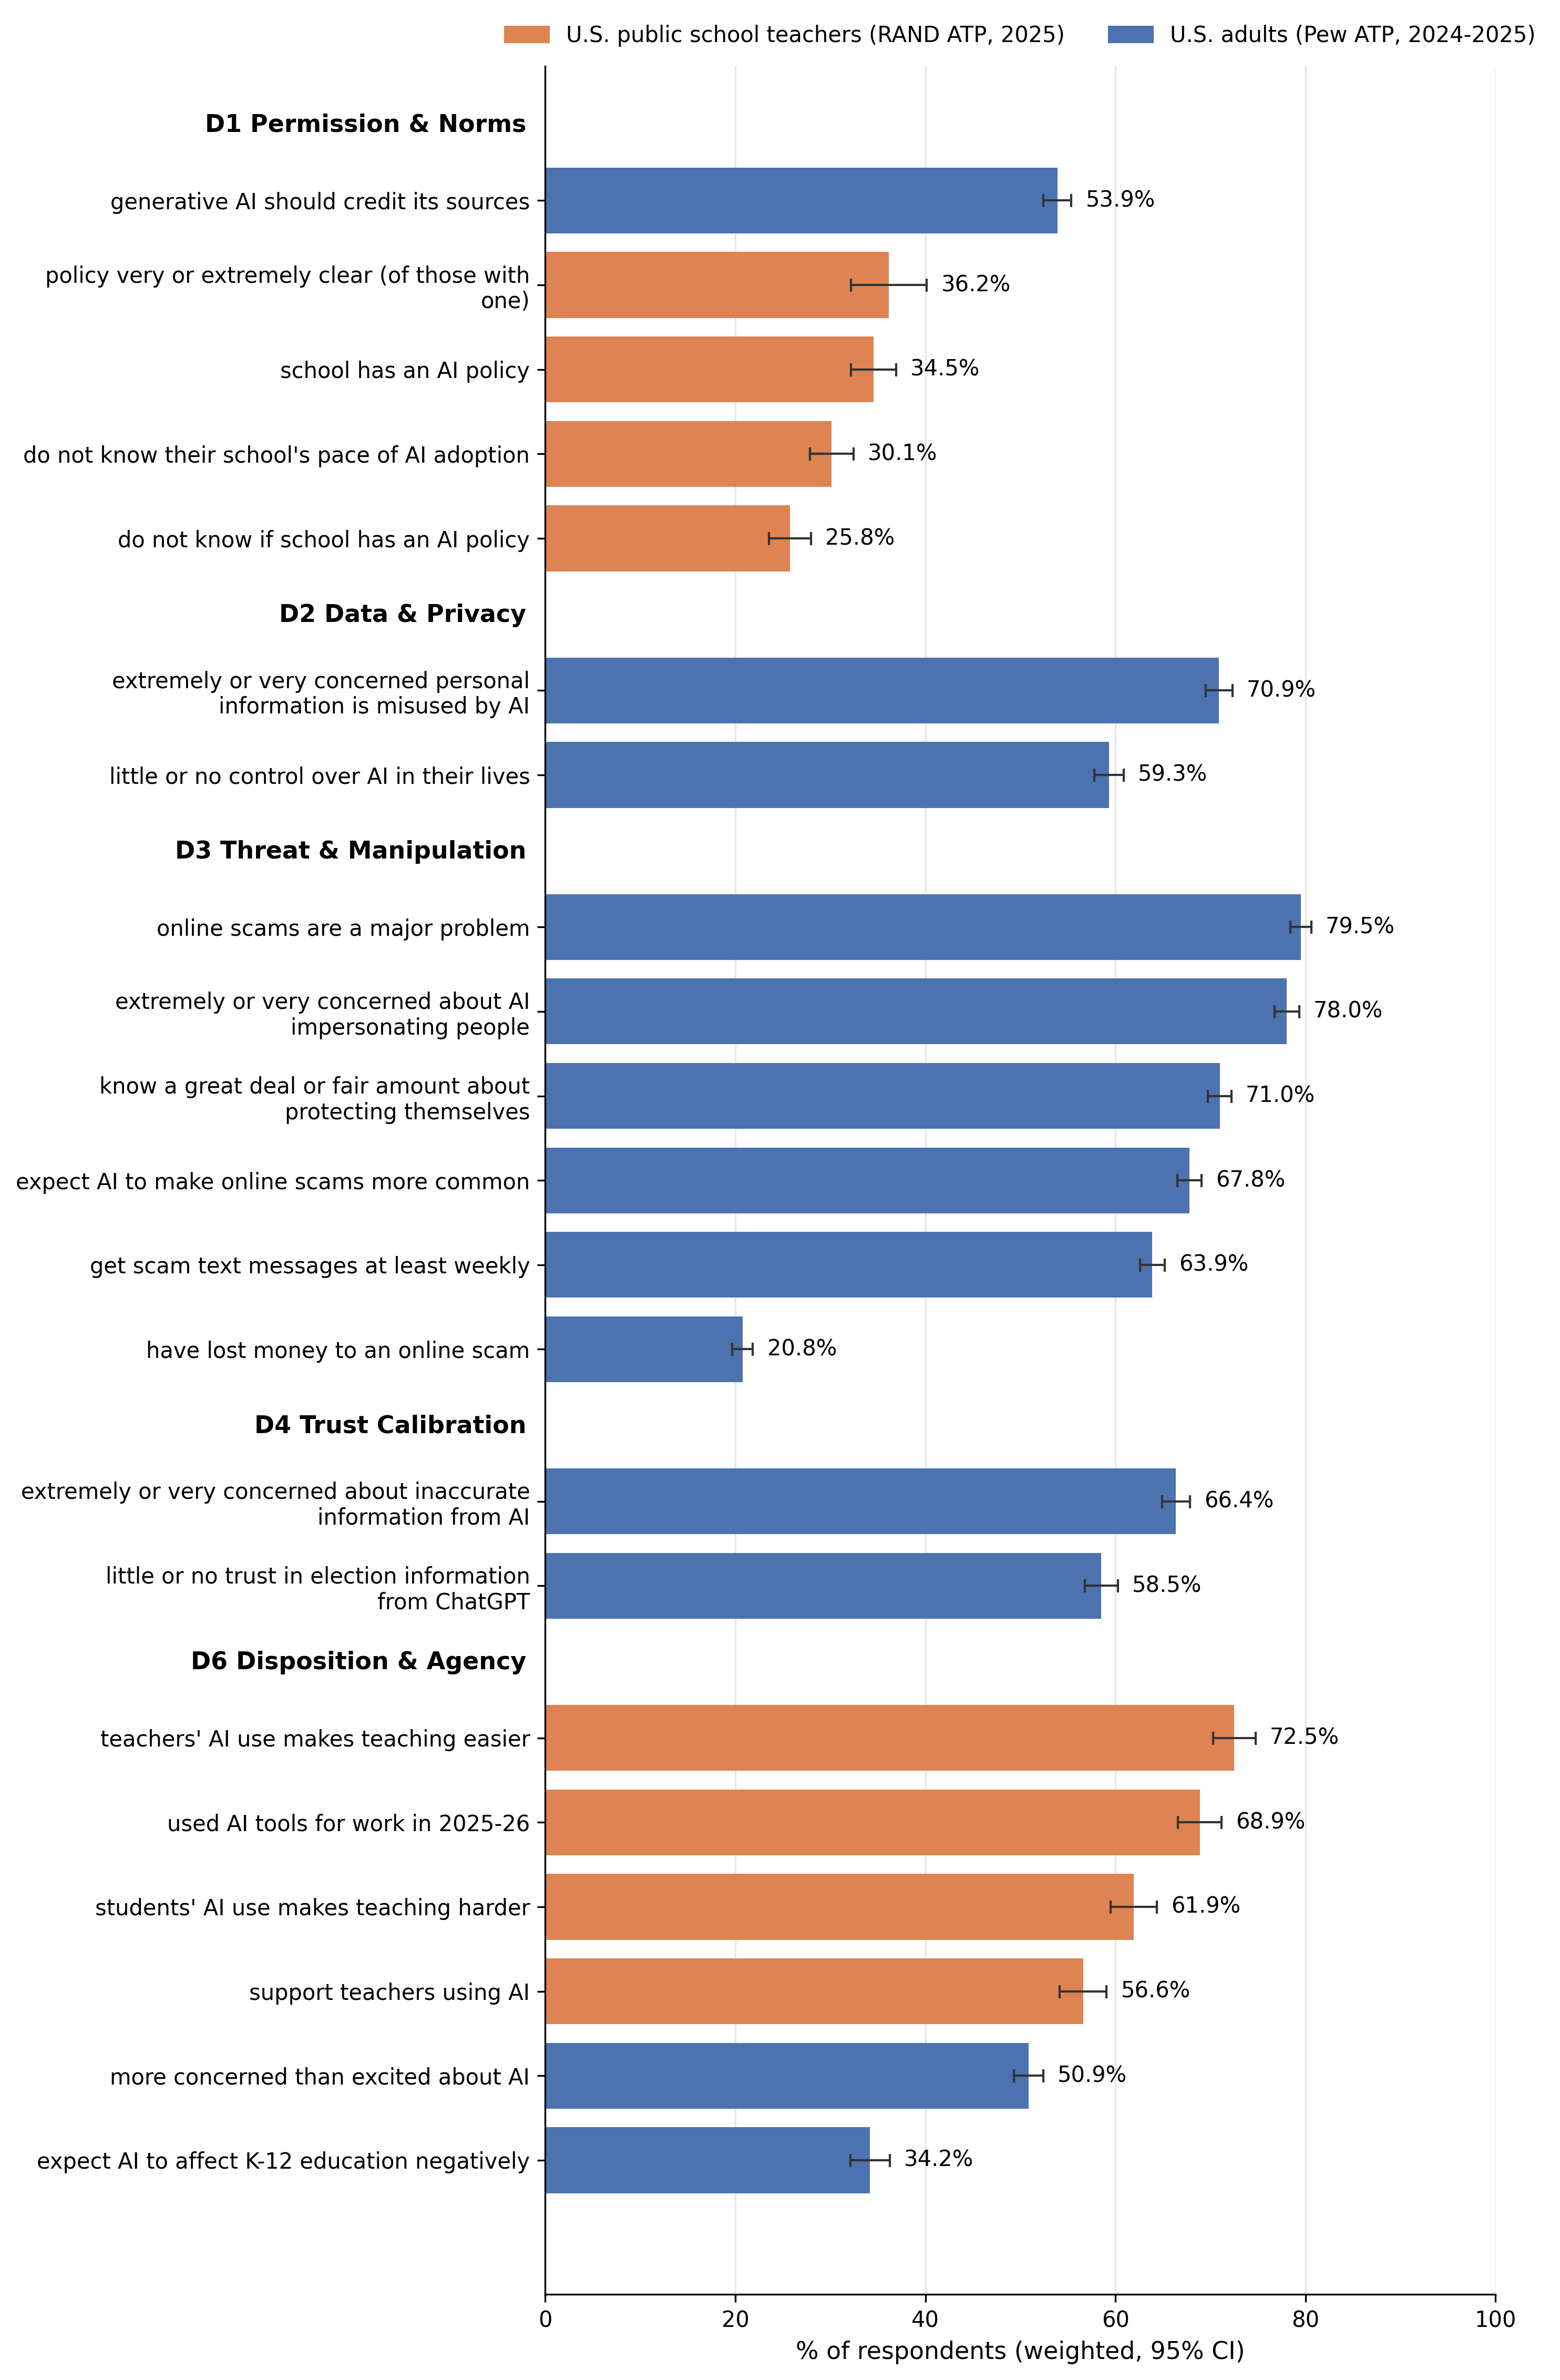

In [23]:
# ============ ADDENDUM F: redraw the Tier 1 figure for print ======================
# Redraws figures/tier1_survey_evidence.jpg from tables/tier1_mapped_results.csv
# (written by Addendum E) with print-legible labels. Reads no survey data and
# changes no numbers. Needs cells 0-3 (Drive paths and the savefig helper).
import os, textwrap
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Patch

res = pd.read_csv(os.path.join(TABDIR, 'tier1_mapped_results.csv'))
DIM_ORDER = ['D1', 'D2', 'D3', 'D4', 'D6']
DIM_NAME = {'D1': 'D1 Permission & Norms', 'D2': 'D2 Data & Privacy',
            'D3': 'D3 Threat & Manipulation', 'D4': 'D4 Trust Calibration',
            'D6': 'D6 Disposition & Agency'}
COL = {'RAND': '#dd8452', 'Pew': '#4c72b0'}

res['who'] = np.where(res.source.str.startswith('RAND'), 'RAND', 'Pew')
res['label'] = (res.description.str.replace(r'^(Teachers|Adults): ', '', regex=True)
                .apply(lambda s: '\n'.join(textwrap.wrap(s, 46))))
res = (res.assign(_d=res.dimension.map({d: i for i, d in enumerate(DIM_ORDER)}))
          .sort_values(['_d', 'share_pct'], ascending=[True, False]).reset_index(drop=True))

# y positions with a gap between dimensions, top to bottom
ypos, y, prev = [], 0.0, None
for d in res.dimension:
    if prev is not None and d != prev:
        y += 0.8
    ypos.append(y); y += 1.0; prev = d
ypos = -np.array(ypos)

fig, ax = plt.subplots(figsize=(10, 0.62 * len(res) + 2.2))
ax.barh(ypos, res.share_pct,
        xerr=[res.share_pct - res.ci_lo, res.ci_hi - res.share_pct],
        color=[COL[w] for w in res.who], height=0.78, capsize=3,
        error_kw={'elinewidth': 1, 'ecolor': '#333333'})
for yy, v, hi in zip(ypos, res.share_pct, res.ci_hi):
    ax.text(min(hi + 1.5, 93), yy, f'{v:.1f}%', va='center', fontsize=10)
ax.set_yticks(ypos, res.label, fontsize=10)
ax.set_xlim(0, 100); ax.set_xlabel('% of respondents (weighted, 95% CI)', fontsize=11)
ax.tick_params(axis='x', labelsize=10)
ax.grid(axis='x', alpha=0.3); ax.set_axisbelow(True)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)

# dimension headers in the left margin, beside each group
for d in DIM_ORDER:
    idx = np.where(res.dimension.values == d)[0]
    if len(idx):
        ax.text(-0.02, ypos[idx].max() + 0.75, DIM_NAME[d], transform=ax.get_yaxis_transform(),
                ha='right', va='bottom', fontsize=11, fontweight='bold')
ax.legend(handles=[Patch(color=COL['RAND'], label='U.S. public school teachers (RAND ATP, 2025)'),
                   Patch(color=COL['Pew'], label='U.S. adults (Pew ATP, 2024-2025)')],
          loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False, fontsize=10)
savefig('tier1_survey_evidence'); plt.show()